# Stage evaluation: how good is every section of the pipeline?

`Single_Image_Run.ipynb` answers "what score do we get and how long does it take". This notebook asks the question one level deeper: **which section loses the points, and how much?** It uses the same pipeline pieces, one photo at a time, but looks at what each stage hands to the next.

**"Found" means: a place within 4 sigma of the truth** (the +3 point band). The strict version, within 1 sigma (+10 points), is always shown next to it. Both numbers are in `FOUND_SIGMA` and `STRICT_SIGMA`.

| Stage | Question | What is measured |
|---|---|---|
| 1. Image processing | Is the photo usable, and does it look like the map where it truly is? | valid share and contrast of the north-up canvas; edge strength; the score of every map at the true place against the rest of the search disc |
| 2. Coarse search | Is the target among the chosen peaks? | recall at K (target anywhere in the first K peaks), rank of the first right peak, does the global maximum of the score map lie at the target |
| 3. Semantic layer (DINO) | Does it help the first place, and does it keep the target when only M of K go on? | top-1 before and after (paired, with interval), recall at M of K, rank of the first right peak, how well the DINO score separates right from wrong places |
| 4. Fine matching | If the target is among the M, does the matcher find it? | inliers of the right candidate against the wrong ones, how often the right one has the most inliers, how often it has none, error after the shift correction |
| 5. Decision | Does it answer the right photos? | precision, answerable photos that were skipped, points lost to skipping and to wrong answers, bar sweep |
| 6. End to end | Where do the points go? | a funnel: all photos, target in K, target in M, right candidate chosen, answered, within 4 sigma, within 1 sigma |

**How it runs, in three passes.** Pass A (Part 3) renders each photo, computes the score maps, the K_MAX best peaks and the DINO scores once. Pass B (Part 4) runs the fine matcher on all K_MAX peaks of every photo once per matcher. Everything after that (the tables and the hyperparameter sweeps of K, M, DINO weight, answer bar, gamma, rescue rule) is calculated from the stored numbers, **without matching again**. Sweeping a hyperparameter therefore costs seconds.

**Read the sweeps with care.** They search many settings on the same 100 photos they are scored on, so the best row is optimistic. Trust a setting only if it also helps in both halves of the photos, and look for a flat region, not a single best row.

The analysis of *every* hyperparameter over wide ranges (borders, margins, confidence, RANSAC, strategies) is a separate notebook: `tests/Stage_Evaluation/Parameter_Test.ipynb`.

**Heading queries (Part 6.7).** The stages above judge one drawing per photo. Part 6.7 draws every photo at several yaw guesses, runs each through the stages, and shows what the pooled candidates gain (set `RUN_HEADINGS = False` to skip it).


**Added 11 Nov (all phases, with time).** The notebook now also follows the later phases of the pipeline and measures how long each one takes, on the same photos:

| Part | Question |
|---|---|
| 6.8 Time | seconds per stage of one query (render, maps, coarse, DINO, fine), and what K and M cost |
| 6.9 Decision steps | the 6 standard queries, answer at the bar, then query agreement, then escalation with the 27 wide queries (Test_Iteration_3): score, wrong answers and seconds of each step, and how the escalation bar and agreement settings change them |
| 6.10 All phases | one table from the single query to the full decision: score, wrong answers, answered, queries and seconds per photo, photos over the 22 s budget and the 30 s limit |

The heading queries of Part 6.7 now run the 27 wide queries once per photo (9 headings x 3 scales); the 6 standard queries, the 9-heading set and every other variant are read out of the same run, so nothing is matched twice. Set `RUN_HEADINGS = False` to skip Parts 6.7 to 6.10.

# Part 1 · Settings

In [1]:
import os, sys, math, time, gc
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
while not (ROOT / "single_photo_pipeline.py").exists():
    ROOT = ROOT.parent                    # walk up to the repo folder
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "src"))
os.chdir(ROOT)

# ------------------------------------------------------------------ settings: change here, run again
DATA = "official"           # "official" (d1 photos) or "nudt" (Changsha test photos)
N_PHOTOS = 500              # photos loaded for the data set (spread over the flights)
N_EVAL = 100                # photos evaluated
FIRST_PHOTO = 0             # the first photo of the window (photos FIRST_PHOTO ... FIRST_PHOTO + N_EVAL - 1): use another window to test a setting on photos it was not tuned on
COARSE = "edge_zncc"        # the coarse method of every query and of the single-query chain: "edge_zncc" (the fusion was dropped: no gain over it) or "fused"
MATCHERS = ["loftr_minima"] # fine matchers to evaluate, e.g. ["roma_minima", "loftr_minima", "lightglue"]. The first one is the baseline in all tables
K_MAX = 100                 # peaks kept per photo and sent through the fine stage once (every K and M of the sweeps is taken from these)
FOUND_SIGMA = 4.0           # a place counts as found when it is within this many sigma of the truth
STRICT_SIGMA = 1.0          # the strict version, shown next to it

# the baseline setting for the stage tables (the sweeps in Part 8 vary these)
USE_SEMANTIC_LAYER = True   # DINO re-orders the K shortlist and the best M go to the fine stage; False = the first M of the coarse order
K_BASE = 100                # K: places the coarse search returns
M_BASE = 25                 # M <= K: places that count as sent to the fine stage
WEIGHT_BASE = 100.0         # DINO weight in the re-ordering: z(coarse) + WEIGHT * z(DINO); 100 = DINO decides inside the K, 0 = coarse order
MIN_INLIERS = 8             # answer bar: answer when the chosen place has at least this many inliers
GAMMA = 1.0                 # choose by  inliers + GAMMA * (DINO z-score);  0 = inliers only
RESCUE_INLIERS = None       # e.g. 6: also answer with this many inliers (instead of MIN_INLIERS) ...
RESCUE_Z = None             # ... when the DINO z-score of the chosen place is at least this (e.g. 2.0)
RANSAC_PIXELS = None        # inlier distance in pixels (None = 3.0 from settings)
MATCHER_CONFIDENCE = 0.21   # LoFTR only: matches below this confidence are dropped before RANSAC (0.2 = kornia's default; lower lets weak, possibly false matches through)
LOFTR_COARSE_THRESHOLD = 0.21  # LoFTR only: its own cut on the coarse match probability (None = 0.2)
LOFTR_BATCH = 5             # LoFTR pairs per network call (1 = one at a time). Measured: 5 is 1.13x faster for 0.95 GB, 10 is 1.17x for 1.7 GB, 30 ran out of memory (Batch_Speed_Check.ipynb); the answers are identical
DINO_BATCH = 25             # DINO map windows per call
QUERY_GROUP = 1             # heading queries whose LoFTR pairs are matched together (1 = each alone); with LOFTR_BATCH it sets how many pairs one call gets

# heading queries (Part 6.7): the photo is also drawn at several guesses of the heading (yaw metadata is off by up to +-10 degrees for some photos, Patch v0.5.6);
# every drawing is its own query through coarse -> DINO -> fine, and the answer is chosen among the candidates of all queries
RUN_HEADINGS = True         # False = skip Part 6.7 (it costs about one extra pass A + B per heading)
HEADINGS = [-10.0, -7.5, -5.0, -2.5, 0.0, 2.5, 5.0, 7.5, 10.0]   # degrees added to the yaw, one query each (0.0 must be in the list: it is the plain query)
SCALE_FACTORS = [0.95, 1.0, 1.05]   # the projection scale is multiplied by each of these (queries = headings x scale factors). 9 x 3 = 27 queries per photo: the wide set of the escalation
HEADING_K = 50              # K per query
HEADING_M = 10              # M per query: the places of each query that go to the fine stage
STANDARD_HEADINGS = [-5.0, 0.0, 5.0]    # the standard queries of the submitted pipeline: 3 headings x 2 scales = 6 queries
STANDARD_SCALES = [1.0, 1.05]
STANDARD_NAME = "standard 6 (-5, 0, +5 x 1.0, 1.05)"
WIDE_NAME = "wide 27 (9 headings x 3 scales)"
HEADING_VARIANTS = {        # name -> (headings, scale factors): scored from the same queries, nothing is run twice
    "plain (heading 0)": ([0.0], [1.0]),
    "3 headings (-5, 0, +5)": ([-5.0, 0.0, 5.0], [1.0]),
    "5 headings (step 5)": ([-10.0, -5.0, 0.0, 5.0, 10.0], [1.0]),
    "9 headings (step 2.5)": (HEADINGS, [1.0]),
    STANDARD_NAME: (STANDARD_HEADINGS, STANDARD_SCALES),
    WIDE_NAME: (HEADINGS, SCALE_FACTORS),
}

# the decision steps after the queries (Part 6.9, Test_Iteration_3/Decision_Report.md)
MIN_AGREE = 2               # answer also when this many of the standard queries found the same place (a query agrees with itself, so at least 2)
AGREE_RADIUS_SIGMA = 1.0    # the same place = within this many sigma
AGREE_QUERY_INLIERS = 3     # a query counts in the agreement only with this many inliers on its own best candidate
ESCALATION_MIN_INLIERS = 11 # a photo still skipped is decided again over the wide queries: answered only with this many inliers
ESCALATION_BARS = [8, 9, 10, 11, 12, 13]    # bars tried for the escalation in the sweep of Part 6.9
AGREE_RADII = [0.5, 1.0, 2.0]               # agreement radii tried in the sweep of Part 6.9
AGREE_MINIMUMS = [2, 3]                     # numbers of agreeing queries tried in the sweep of Part 6.9
GUARD_PRIOR = 0.169             # inflation guard: mean inliers of a wrong place (more than 4 sigma from the answer) on the development photos, from the 6 standard queries
GUARD_PRIOR_WEIGHT = 30         # the prior counts like this many photos
GUARD_DEAD_ZONE = 1.5           # the bars rise only when the running level is more than this many times the prior
INFLATION_FACTORS = [1.0, 1.25, 1.5, 2.0]       # stress test of Part 6.9: every inlier count multiplied by this, the decision without and with the guard

# time: one photo has 30 s on the Jetson, a later answer counts as no_match; the submitted code stops starting queries after 22 s
TIME_BUDGET_S = 22
TIME_LIMIT_S = 30

# the values the sweeps in Part 8 go through: one logical range per hyperparameter (the baseline above should lie inside it)
K_LIST = [5, 10, 25, 50, 100, 150, 200]          # places the coarse search returns (values above K_MAX are skipped)
M_LIST = [1, 3, 5, 10, 15, 25, 50]               # places sent to the fine stage (1 = trust the first place; M > K is skipped)
WEIGHT_LIST = [0.0, 0.3, 1.0, 3.0, 10.0, 100.0]  # DINO weight in the re-ordering: 0 = coarse order ... 100 = DINO decides
BAR_MIN = 4                                      # the answer bar is swept from BAR_MIN to BAR_MAX in steps of BAR_STEP (inliers the chosen place needs)
BAR_MAX = 16
BAR_STEP = 3
BAR_LOW = []                                     # extra low bars (not used here: they are not safe with this matcher)
BAR_LIST = sorted(set(BAR_LOW + list(range(BAR_MIN, BAR_MAX + 1, BAR_STEP))))      # 1, 2, 3, 4, 7, 10, 13, 16
GAMMA_LIST = [0.0, 0.25, 0.5, 1.0, 2.0, 4.0]     # weight of the DINO z-score when choosing the candidate (0 = inliers only)
RESCUE_LIST = [None, (4, 2.0), (6, 2.0), (8, 2.5)]   # (inliers, DINO z): also answer with fewer inliers when DINO is sure

# What changes the data itself (MAP, COARSE, MATCHERS, N_EVAL) needs a new run of the notebook.

N_SAMPLES = 4               # sample figures per kind of failure (Part 9)
SEED = 451
plt.rcParams["figure.dpi"] = 90

assert FIRST_PHOTO >= 0, "FIRST_PHOTO must be 0 or more"
assert FOUND_SIGMA > STRICT_SIGMA > 0, "need FOUND_SIGMA > STRICT_SIGMA > 0"
assert len(MATCHERS) >= 1, "give at least one matcher"
assert LOFTR_BATCH >= 1 and DINO_BATCH >= 1 and QUERY_GROUP >= 1, "the batch settings must be 1 or more"
assert K_MAX >= K_BASE, "K_MAX must be at least K_BASE"
K_LIST = [k for k in K_LIST if k <= K_MAX]
assert 1 <= M_BASE <= K_BASE, "need 1 <= M_BASE <= K_BASE"
assert (RESCUE_INLIERS is None) == (RESCUE_Z is None), "give RESCUE_INLIERS and RESCUE_Z together"
assert 1 <= BAR_MIN <= BAR_MAX and BAR_STEP >= 1, "need 1 <= BAR_MIN <= BAR_MAX and BAR_STEP >= 1"
assert LOFTR_COARSE_THRESHOLD is None or 0 < LOFTR_COARSE_THRESHOLD < 1, "LOFTR_COARSE_THRESHOLD must be between 0 and 1 (or None)"
assert 0.0 in HEADINGS and 1.0 in SCALE_FACTORS, "the plain query (heading 0, scale factor 1) is the baseline and must be in the lists"
assert MIN_AGREE >= 2, "MIN_AGREE must be at least 2 (a query always agrees with itself)"
assert ESCALATION_MIN_INLIERS >= MIN_INLIERS, "the escalation bar must not be below the normal bar"
assert 1 <= HEADING_M <= HEADING_K, "need 1 <= HEADING_M <= HEADING_K"


# Part 2 · Set up once

The same pieces as `single_photo_pipeline.py`: photos and camera, the map at all zoom levels, the feature families, the trained fusion model, the DINO network and the first matcher. Here the pipeline object is used as a **toolbox** (its parts are called one by one), not as a single call, because we want to see what every stage produced.

In [2]:
from single_photo_pipeline import SinglePhotoPipeline      # first import: it saves the development-set settings before NUDT changes them
import cv2
import torch
from header import settings
from header.settings import DEVICE
from train import config
from src.header.scoring import points_for_error, final_score
from image_processing.geometry import render_query
from image_processing.map_levels import level_for_height, map_piece
from image_processing.edge_features import query_edge_features
from image_processing.thermal import load_thermal_frame, normalise_frame
from train.coarse_methods.inputs import make_inputs
from train.coarse_methods.single_map import make_single_map_method
from semantic_rerank.dino_rerank import shortlist_peaks, dino_candidate_scores, rerank_peaks
from semantic_rerank.decision import shortlist_z, choose_candidate, decide_with_dino
from fine_matching.second_stage_any import run_fine_stage

pipeline = SinglePhotoPipeline(DATA, COARSE, semantic_layer=True, semantic_decision=True, k_peaks=K_MAX, m_fine=K_MAX,
                               matcher=MATCHERS[0], min_inliers=MIN_INLIERS, ransac_pixels=RANSAC_PIXELS,
                               matcher_confidence=MATCHER_CONFIDENCE, loftr_coarse_threshold=LOFTR_COARSE_THRESHOLD, loftr_batch=LOFTR_BATCH, dino_batch=DINO_BATCH)
start = time.time()
pipeline.setup(N_PHOTOS, SEED)
print("setup done in %.1f s" % (time.time() - start))
for line in pipeline.describe():
    print(line)

test_set = pipeline.test_set
camera = pipeline.camera
level_images = pipeline.level_images

# the coarse methods that are evaluated: the fused one (or edge_zncc if there is no saved fusion model) and edge_zncc alone
PRIMARY = pipeline.coarse_name
METHODS = {"edge_zncc": make_single_map_method("edge_zncc")}
if PRIMARY != "edge_zncc":
    METHODS[PRIMARY] = pipeline.coarse_method
print("coarse methods evaluated:", list(METHODS), "| the fine stage runs on:", PRIMARY)
print("maps inside the fusion:", pipeline.names)

level 3: 0.85 m/pixel, picture 16378 x 16004, map coverage 100%
level 4: 1.20 m/pixel, picture 11581 x 11316, map coverage 100%
level 5: 1.70 m/pixel, picture 8189 x 8002, map coverage 100%
level 6: 2.40 m/pixel, picture 5790 x 5658, map coverage 100%
level 7: 3.39 m/pixel, picture 4094 x 4001, map coverage 100%
map store ready, took 111 s


/home/voidness/Storage/Synced Folders/InterIIT Tech 15/venv-geoloc/lib/python3.10/site-packages/kornia/feature/lightglue.py:44: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @torch.cuda.amp.custom_fwd(cast_inputs=torch.float32)
/home/voidness/Storage/Synced Folders/InterIIT Tech 15/venv-geoloc/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


setup done in 125.9 s
data: official | 379 photos available | zoom levels [3, 4, 5, 6, 7]
photos: official | map: new
coarse method: edge_zncc | maps: ['edge_zncc']
semantic layer: on (best K=100 -> M=100) | DINO in the decision: on (gamma 1.00, rescue (None, None))
fine matcher: loftr_minima | answer bar: 8 inliers | RANSAC 3.0 px | matcher confidence 0.21 | LoFTR coarse threshold 0.21, upscale 1.0 | border 0 px, margin 0 px
DINO order weight: 100.0 | projection overrides: none (settings.GEOMETRY)
batches: 5 LoFTR pairs and 25 DINO places per call
device: cuda
coarse methods evaluated: ['edge_zncc'] | the fine stage runs on: edge_zncc
maps inside the fusion: ['edge_zncc']


# Part 3 · Pass A: photo, score maps, peaks and DINO scores (no matcher yet)

For every photo, without the matcher:

1. **Render** the north-up canvas. Keep its valid share, contrast and edge strength (stage 1).
2. **Score maps.** For each map in the fusion and for each coarse method, find where in the 5 km disc the best score lies relative to the truth: `truth_stats` gives the global maximum's distance from the truth (in sigma), and the best score within 4 sigma of the truth against the rest of the disc (a z-score and a margin).
3. **Peaks.** For each coarse method, the K_MAX best peaks, their error in sigma, and the DINO scores of those places.

The truth is used only to judge. Nothing the pipeline does depends on it.

In [3]:
def clock_now():
    # seconds, with the GPU finished first so that the reading belongs to the stage just run
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    return time.perf_counter()


def errors_in_sigma(peaks, index):
    assert peaks.ndim == 2 and peaks.shape[1] >= 3, "peaks must be (n, >= 3)"
    truth = test_set.truths[index]
    sigma = test_set.sigmas[index]
    errors = np.full(len(peaks), 1e9)
    for k in range(len(peaks)):
        if peaks[k, 1] < 1e8:
            errors[k] = math.hypot(peaks[k, 1] - truth[0], peaks[k, 2] - truth[1]) / sigma
    return errors


def truth_stats(score_map, usable, geometry, truth, sigma):
    # What does this score map say about the true place?
    #   argmax_err  distance (in sigma) of the highest score of the whole disc from the truth
    #   near_z      z-score (over the disc) of the best score within FOUND_SIGMA of the truth
    #   margin      best score near the truth minus best score elsewhere (positive = the truth area wins)
    assert score_map.shape == usable.shape == geometry["inside"].shape, "score map, usable mask and grid must have the same shape"
    assert sigma > 0, "sigma must be positive"
    empty = dict(argmax_err=np.nan, near_z=np.nan, margin=np.nan)
    if int(usable.sum()) < 10:
        return empty
    x_m = geometry["x_m"]
    y_m = geometry["y_m"]
    distance_sq = (x_m[None, :] - truth[0]) ** 2 + (y_m[:, None] - truth[1]) ** 2
    values = score_map[usable]
    mean = float(values.mean())
    spread = float(values.std()) + 1e-9

    masked = score_map.clone()
    masked[~usable] = -1e9
    best_flat = int(masked.reshape(-1).argmax())
    row = best_flat // score_map.shape[1]
    col = best_flat % score_map.shape[1]
    argmax_err = math.hypot(float(x_m[col]) - truth[0], float(y_m[row]) - truth[1]) / sigma

    near = usable & (distance_sq <= (FOUND_SIGMA * sigma) ** 2)
    far = usable & (distance_sq > (FOUND_SIGMA * sigma) ** 2)
    if int(near.sum()) == 0 or int(far.sum()) == 0:
        return dict(argmax_err=argmax_err, near_z=np.nan, margin=np.nan)
    near_best = float(masked[near].max())
    far_best = float(masked[far].max())
    return dict(argmax_err=argmax_err, near_z=(near_best - mean) / spread, margin=near_best - far_best)

In [4]:
records = []
failures = []
assert FIRST_PHOTO < len(test_set.items), "FIRST_PHOTO %d is beyond the %d photos" % (FIRST_PHOTO, len(test_set.items))
count = min(N_EVAL, len(test_set.items) - FIRST_PHOTO)
start = time.time()
for index in range(FIRST_PHOTO, FIRST_PHOTO + count):
    try:
        item = test_set.items[index]
        truth = test_set.truths[index]
        sigma = test_set.sigmas[index]
        cv2.setRNGSeed(settings.SEED)
        clock = clock_now()
        level = level_for_height(item["rel_height"], camera)
        canvas, valid = render_query(item, camera, level)
        render_seconds = clock_now() - clock
        assert valid.any(), "the canvas has no valid pixel"

        query_features, query_cells = query_edge_features(canvas, valid)
        cells_ok = np.asarray(query_cells) > 0
        edge_strength = 0.0
        if cells_ok.any():
            edge_strength = float(query_features.sum(axis=0)[cells_ok].mean())

        clock = clock_now()
        inputs = make_inputs(canvas, valid, level, test_set.priors[index], pipeline.families, pipeline.names)
        maps_seconds = clock_now() - clock
        geometry = inputs["geometry"]
        record = dict(index=index, height=item["rel_height"], level=level, truth=truth, sigma=sigma,
                      canvas=canvas, valid=valid, valid_frac=float(valid.mean()), contrast=float(canvas[valid].std()),
                      edge_strength=edge_strength, maps={}, methods={}, seconds=dict(render=render_seconds, maps=maps_seconds))

        for name in pipeline.names:
            raw = inputs["maps"][name]
            usable = inputs["usable"] & (raw > -1)
            record["maps"][name] = truth_stats(raw, usable, geometry, truth, sigma)

        for method_name, method in METHODS.items():
            clock = clock_now()
            score_map = method(inputs)
            coarse_seconds = clock_now() - clock
            usable = geometry["inside"] & (score_map > -1)
            stats = truth_stats(score_map, usable, geometry, truth, sigma)
            clock = clock_now()
            short = shortlist_peaks(score_map, geometry, K_MAX)
            pooled, dense = dino_candidate_scores(pipeline.encoder, canvas, valid, level_images, level, short)
            semantic_seconds = clock_now() - clock
            record["methods"][method_name] = dict(stats=stats, short=short, dense=dense, pooled=pooled, err=errors_in_sigma(short, index),
                                                  seconds=dict(coarse=coarse_seconds, semantic=semantic_seconds))
        records.append(record)
        del inputs
    except Exception as error:
        failures.append(dict(photo=index, error="%s: %s" % (type(error).__name__, str(error)[:120])))
        print("photo %d failed: %s: %s" % (index, type(error).__name__, str(error)[:120]))
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    if (index - FIRST_PHOTO + 1) % 20 == 0:
        print("pass A: photo %d/%d, %.0f s" % (index - FIRST_PHOTO + 1, count, time.time() - start))

record_by_index = {record["index"]: record for record in records}
print("pass A done: %d photos in %.0f s (%d failed)" % (len(records), time.time() - start, len(failures)))
assert len(records) > 0, "no photo went through pass A"

pass A: photo 20/100, 10 s
pass A: photo 40/100, 18 s
pass A: photo 60/100, 26 s
pass A: photo 80/100, 35 s
pass A: photo 100/100, 44 s
pass A done: 100 photos in 44 s (0 failed)


# Part 4 · Pass B: the fine matcher on every peak, once per matcher

The matcher runs on all K_MAX peaks of the **primary coarse method**, in the order the coarse search gave them. Inliers and shifts are stored per peak. Because every candidate is judged on its own, any later choice of K, M, DINO weight or answer bar only picks rows out of these numbers. For several matchers the models are loaded one after the other, so only one is in the GPU at a time.

For `loftr_minima` the raw matches of every candidate (positions and confidence) are kept as well, so Part 8.4 can change the confidence cut and the RANSAC distance without running the network again.

In [5]:
def load_fine_matcher(name):
    assert name in ("lightglue", "loftr_minima", "roma_minima"), "unknown matcher %r" % (name,)
    checkpoints = config.find_nudt_dir() / "checkpoint"
    if name == "loftr_minima":
        from fine_matching.loftr_matcher import load_loftr_matcher
        return load_loftr_matcher(checkpoints / "MINIMA" / "minima_loftr.ckpt", MATCHER_CONFIDENCE, 1.0, LOFTR_COARSE_THRESHOLD, 0, 0, LOFTR_BATCH)
    if name == "roma_minima":
        from fine_matching.roma_matcher import load_roma_matcher
        return load_roma_matcher(checkpoints / "MINIMA" / "minima_roma.pth", checkpoints / "RoMa" / "dinov2_vitl14_pretrain.pth")
    from fine_matching.matcher import load_matcher
    settings.MINIMA_FILE = checkpoints / "MINIMA" / "minima_lightglue.pth"
    return load_matcher()


from fine_matching.loftr_matcher import candidate_matches, stage2_from_matches

fine = {}
fine_seconds = {}
fine_photo_seconds = {}     # name -> photo -> seconds of the fine stage for all K_MAX peaks of that photo
raw_matches = {}      # LoFTR only: the raw matches of every candidate, so that the confidence cut and the RANSAC distance can be swept without the network
for name in MATCHERS:
    if name == MATCHERS[0]:
        matcher = pipeline.matcher
    else:
        matcher = load_fine_matcher(name)
    stored = {}
    photo_seconds = {}
    start = time.time()
    for position, record in enumerate(records):
        short = record["methods"][PRIMARY]["short"]
        photo_clock = clock_now()
        if name == "loftr_minima":
            cv2.setRNGSeed(settings.SEED)
            kept = candidate_matches(matcher, record["canvas"], record["valid"], record["level"], short, level_images)
            raw_matches.setdefault(name, {})[record["index"]] = kept
            stage2 = stage2_from_matches(kept, record["level"], matcher.min_confidence)
        else:
            stage2 = run_fine_stage(matcher, record["canvas"], record["valid"], record["level"], short, level_images)
        assert len(stage2["inliers"]) == len(short), "the fine stage must return one inlier count per peak"
        photo_seconds[record["index"]] = clock_now() - photo_clock
        stored[record["index"]] = dict(inliers=np.asarray(stage2["inliers"], dtype=float), shifts=np.asarray(stage2["shifts"], dtype=float))
        if (position + 1) % 20 == 0:
            print("pass B (%s): photo %d/%d, %.0f s" % (name, position + 1, len(records), time.time() - start))
    fine[name] = stored
    fine_photo_seconds[name] = photo_seconds
    fine_seconds[name] = time.time() - start
    print("pass B (%s) done in %.0f s: %.2f s per photo for %d candidates" % (name, fine_seconds[name], fine_seconds[name] / len(records), K_MAX))
    if name != MATCHERS[0]:
        del matcher
        gc.collect()
        if DEVICE == "cuda":
            torch.cuda.empty_cache()

pass B (loftr_minima): photo 20/100, 70 s
pass B (loftr_minima): photo 40/100, 140 s
pass B (loftr_minima): photo 60/100, 210 s
pass B (loftr_minima): photo 80/100, 280 s
pass B (loftr_minima): photo 100/100, 350 s
pass B (loftr_minima) done in 350 s: 3.50 s per photo for 100 candidates


# Part 5 · Scoring tools (no GPU, no matcher)

Everything below works on the stored numbers.

* `ordered_errors` : for a setting (K, M, layer, weight) the order in which the peaks go to the fine stage, and the error of each. With the layer on this is the same re-ordering as `semantic_layer` (`rerank_peaks` over the first K peaks); with the layer off it is the first M of the coarse order. The position in the shortlist is carried in column 3 of a copy of the peaks, because `rerank_peaks` does not use that column.
* `answer_for` : the answer for one photo under one setting (choose the candidate, decide, score), the same rules as `single_photo_pipeline.py`.
* `evaluate` : `answer_for` for every photo, as a table.
* `summarise` : one line of numbers for a table of settings.

In [6]:
def ordered_errors(record, method_name, K, M, layer, weight):
    assert 1 <= M <= K <= K_MAX, "need 1 <= M <= K <= K_MAX, got M=%s K=%s" % (M, K)
    assert weight >= 0, "weight must be >= 0"
    data = record["methods"][method_name]
    if not layer:
        order = np.arange(M)
    else:
        sub = data["short"][:K].copy()
        sub[:, 3] = np.arange(K)                 # column 3 carries the position in the shortlist
        order = rerank_peaks(sub, data["dense"][:K], weight, keep=M)[:, 3].astype(int)
    return order, data["err"][order]


def answer_for(record, fine_one, cfg):
    assert set(cfg) >= {"K", "M", "layer", "weight", "gamma", "rescue", "bar"}, "cfg needs K, M, layer, weight, gamma, rescue, bar"
    data = record["methods"][PRIMARY]
    order, errors = ordered_errors(record, PRIMARY, cfg["K"], cfg["M"], cfg["layer"], cfg["weight"])
    peaks = data["short"][order]
    z_short = shortlist_z(data["dense"][:cfg["K"]]) if cfg["layer"] else np.zeros(cfg["K"])
    z = z_short[order]
    stage2 = dict(inliers=fine_one["inliers"][order], shifts=fine_one["shifts"][order])
    gamma = cfg["gamma"] if cfg["layer"] else 0.0
    rescue = cfg["rescue"] if cfg["layer"] else None
    x, y, inliers, chosen, z_chosen = choose_candidate(peaks, stage2, z, gamma)
    if rescue is None:
        answered = decide_with_dino(inliers, z_chosen, min_inliers=cfg["bar"])
    else:
        answered = decide_with_dino(inliers, z_chosen, rescue[0], rescue[1], min_inliers=cfg["bar"])
    truth = record["truth"]
    error_m = math.hypot(x - truth[0], y - truth[1])
    earned = points_for_error(error_m, record["height"], camera.fx)
    all_errors = data["err"][:cfg["K"]]
    row = dict(photo=record["index"], in_K=bool((all_errors <= FOUND_SIGMA).any()), in_M=bool((errors <= FOUND_SIGMA).any()),
               in_M_strict=bool((errors <= STRICT_SIGMA).any()), top1_ok=bool(errors[0] <= FOUND_SIGMA),
               chosen_right=bool(errors[chosen] <= FOUND_SIGMA), answered=bool(answered), inliers=float(inliers),
               z_chosen=float(z_chosen), err_sigma=error_m / record["sigma"], would_earn=earned,
               points=earned if answered else 0,
               chosen_rank=int(order[chosen]), top_first=bool(chosen == 0),               # position of the chosen place in the coarse order; was it the first place after the DINO order?
               dx_m=float(x - truth[0]), dy_m=float(y - truth[1]), err_m=error_m, height=float(record["height"]))   # signed east / north error, for the bias analysis (S7)
    details = dict(order=order, errors=errors, chosen=chosen, x=x, y=y)
    return row, details


def evaluate(cfg, matcher_name):
    assert matcher_name in fine, "matcher %r was not run in pass B" % (matcher_name,)
    rows = []
    for record in records:
        row, details = answer_for(record, fine[matcher_name][record["index"]], cfg)
        rows.append(row)
    return pd.DataFrame(rows)


def summarise(table):
    assert len(table) > 1, "need at least two photos"
    half = len(table) // 2
    answered = table["answered"]
    answered_ok = answered & (table["err_sigma"] <= FOUND_SIGMA)
    result = {}
    result["score (/60)"] = final_score(list(table["points"]))
    result["first half"] = final_score(list(table["points"][:half]))
    result["second half"] = final_score(list(table["points"][half:]))
    result["answered"] = answered.mean()
    result["target in K"] = table["in_K"].mean()
    result["target in M"] = table["in_M"].mean()
    result["top-1 ok"] = table["top1_ok"].mean()
    if table["in_M"].any():
        result["right chosen | target in M"] = table["chosen_right"][table["in_M"]].mean()
    else:
        result["right chosen | target in M"] = np.nan
    result["answered and ok"] = answered_ok.mean()
    result["wrong answers"] = int((table["points"] < 0).sum())
    result["right but skipped"] = int(((~answered) & (table["err_sigma"] <= FOUND_SIGMA)).sum())
    return result


BASE = dict(K=K_BASE, M=M_BASE, layer=USE_SEMANTIC_LAYER, weight=WEIGHT_BASE, gamma=GAMMA,
            rescue=None if RESCUE_INLIERS is None else (RESCUE_INLIERS, RESCUE_Z), bar=MIN_INLIERS)
base = {name: evaluate(BASE, name) for name in MATCHERS}
print("baseline setting:", BASE)
display(pd.DataFrame({name: summarise(base[name]) for name in MATCHERS}).T.round(3))

baseline setting: {'K': 100, 'M': 25, 'layer': True, 'weight': 100.0, 'gamma': 1.0, 'rescue': None, 'bar': 8}


,answered,answered and ok,first half,right but skipped,right chosen | target in M,score (/60),second half,target in K,target in M,top-1 ok,wrong answers
loftr_minima,0.71,0.7,40.56,15.0,0.966,39.6,38.64,0.88,0.88,0.86,1.0


# Part 6 · The stages one by one

## 6.1 Stage 1 · Image processing

Two questions: is the canvas a usable picture (valid share, contrast, edge strength), and does it look like the map **where it truly is**? The second one is measured on the score maps: if the true place does not stand out in a map, no search on top of that map can find it. For each map:

* **max at target (4σ / 1σ)**: the highest score of the whole disc lies within 4 (1) sigma of the truth. This is the strongest test: the map alone would give the right answer.
* **z near truth**: how many standard deviations above the disc's mean the best score near the truth is. Above 3 means the truth area is clearly visible in the map.
* **margin > 0**: the truth area holds a higher score than everything else.

,mean,min,25%,50%,75%,max
height,204.067,100.000,120.225,150.250,299.900,350.700
level,4.810,3.000,4.000,4.000,6.000,7.000
valid_frac,0.770,0.638,0.716,0.758,0.844,0.910
contrast,0.194,0.163,0.182,0.192,0.207,0.237
edge_strength,1.022,0.939,1.013,1.022,1.041,1.076
near_z (edge_zncc),8.804,2.663,6.161,8.916,11.003,18.246


,map,max at target (4 sigma),max at target (1 sigma),median z near truth,z near truth > 3,margin > 0
0,edge_zncc,0.76,0.63,8.916,0.97,0.76


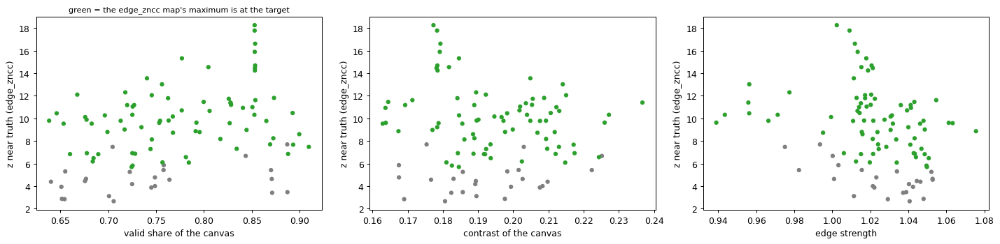

share of photos whose edge_zncc maximum is at the target, by valid share of the canvas:


,mean,count
valid_group,,
low valid share,0.647,34
middle,0.818,33
high valid share,0.818,33


In [7]:
photo_rows = []
for record in records:
    row = dict(photo=record["index"], height=record["height"], level=record["level"], valid_frac=record["valid_frac"],
               contrast=record["contrast"], edge_strength=record["edge_strength"])
    row["near_z (%s)" % PRIMARY] = record["methods"][PRIMARY]["stats"]["near_z"]
    photo_rows.append(row)
image_table = pd.DataFrame(photo_rows)
display(image_table.drop(columns=["photo"]).describe().T[["mean", "min", "25%", "50%", "75%", "max"]].round(3))

all_map_names = list(pipeline.names)
for method_name in METHODS:
    if method_name not in all_map_names:
        all_map_names.append(method_name)
map_rows = []
for name in all_map_names:
    stats = []
    for record in records:
        if name in record["maps"]:
            stats.append(record["maps"][name])
        else:
            stats.append(record["methods"][name]["stats"])
    argmax_err = np.array([s["argmax_err"] for s in stats])
    near_z = np.array([s["near_z"] for s in stats])
    margin = np.array([s["margin"] for s in stats])
    map_rows.append({"map": name,
                     "max at target (4 sigma)": np.nanmean(argmax_err <= FOUND_SIGMA),
                     "max at target (1 sigma)": np.nanmean(argmax_err <= STRICT_SIGMA),
                     "median z near truth": np.nanmedian(near_z),
                     "z near truth > 3": np.nanmean(near_z > 3),
                     "margin > 0": np.nanmean(margin > 0)})
map_table = pd.DataFrame(map_rows)
display(map_table.round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
hit = np.array([record["methods"][PRIMARY]["stats"]["argmax_err"] <= FOUND_SIGMA for record in records])
for axis, column, label in ((axes[0], "valid_frac", "valid share of the canvas"), (axes[1], "contrast", "contrast of the canvas"), (axes[2], "edge_strength", "edge strength")):
    axis.scatter(image_table[column], image_table["near_z (%s)" % PRIMARY], c=["tab:green" if h else "tab:gray" for h in hit], s=16)
    axis.set_xlabel(label)
    axis.set_ylabel("z near truth (%s)" % PRIMARY)
axes[0].set_title("green = the %s map's maximum is at the target" % PRIMARY, fontsize=9)
plt.tight_layout()
plt.show()

image_table["valid_group"] = pd.qcut(image_table["valid_frac"].rank(method="first"), 3, labels=["low valid share", "middle", "high valid share"])
image_table["map_hit"] = hit
print("share of photos whose %s maximum is at the target, by valid share of the canvas:" % PRIMARY)
display(image_table.groupby("valid_group", observed=True)["map_hit"].agg(["mean", "count"]).round(3))

## 6.2 Stage 2 · Coarse search: is the target among the chosen peaks?

**Recall at K** = the share of photos with a peak within 4 sigma (1 sigma) of the truth among the first K peaks. Recall at K = 1 is the coarse top-1. The gap between recall at 1 and recall at 50 is what a better judge of the shortlist (stage 3) could still win; the gap between recall at 50 and 100 % is lost for good at this stage.

,method,found within,recall@1,recall@3,recall@5,recall@10,recall@25,recall@50
0,edge_zncc,4 sigma,0.76,0.82,0.85,0.85,0.86,0.88
1,edge_zncc,1 sigma,0.63,0.67,0.69,0.69,0.70,0.72


edge_zncc: the target is in the first 100 peaks for 88 of 100 photos; rank of the first right peak: median 1, mean 2.4


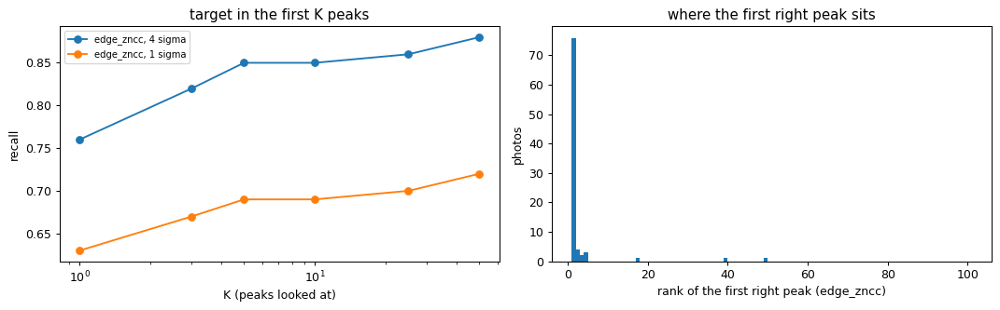

z of the best score near the truth: photos where the target is NOT in the 100 peaks: median 3.67 | photos where it is: median 9.59
(a low value means the map itself did not show the target: a stage 1 / map problem; a high value means the target was visible but another place was ranked higher)


In [8]:
recall_ks = [k for k in (1, 3, 5, 10, 25, 50) if k <= K_MAX]
rows = []
curves = {}
for method_name in METHODS:
    for sigma_limit, label in ((FOUND_SIGMA, "%g sigma" % FOUND_SIGMA), (STRICT_SIGMA, "%g sigma" % STRICT_SIGMA)):
        row = {"method": method_name, "found within": label}
        values = []
        for k in recall_ks:
            hits = [(record["methods"][method_name]["err"][:k] <= sigma_limit).any() for record in records]
            row["recall@%d" % k] = np.mean(hits)
            values.append(np.mean(hits))
        rows.append(row)
        curves[(method_name, label)] = values
display(pd.DataFrame(rows).round(3))

first_right = []
for record in records:
    errors = record["methods"][PRIMARY]["err"]
    right = np.where(errors <= FOUND_SIGMA)[0]
    if len(right) > 0:
        first_right.append(int(right[0]) + 1)
print("%s: the target is in the first %d peaks for %d of %d photos; rank of the first right peak: median %.0f, mean %.1f" % (
    PRIMARY, K_MAX, len(first_right), len(records), np.median(first_right) if first_right else float("nan"), np.mean(first_right) if first_right else float("nan")))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for (method_name, label), values in curves.items():
    axes[0].plot(recall_ks, values, "o-", label="%s, %s" % (method_name, label))
axes[0].set_xscale("log")
axes[0].set_xlabel("K (peaks looked at)")
axes[0].set_ylabel("recall")
axes[0].set_title("target in the first K peaks")
axes[0].legend(fontsize=8)
axes[1].hist(first_right, bins=range(1, K_MAX + 2), color="tab:blue")
axes[1].set_xlabel("rank of the first right peak (%s)" % PRIMARY)
axes[1].set_ylabel("photos")
axes[1].set_title("where the first right peak sits")
plt.tight_layout()
plt.show()

misses = [record for record in records if not (record["methods"][PRIMARY]["err"][:K_MAX] <= FOUND_SIGMA).any()]
missed_photos = set(record["index"] for record in misses)
hits_list = [record for record in records if record["index"] not in missed_photos]
if len(misses) > 0 and len(hits_list) > 0:
    print("z of the best score near the truth: photos where the target is NOT in the %d peaks: median %.2f | photos where it is: median %.2f" % (
        K_MAX, np.nanmedian([record["methods"][PRIMARY]["stats"]["near_z"] for record in misses]),
        np.nanmedian([record["methods"][PRIMARY]["stats"]["near_z"] for record in hits_list])))
    print("(a low value means the map itself did not show the target: a stage 1 / map problem; a high value means the target was visible but another place was ranked higher)")

## 6.3 Stage 3 · Semantic layer (DINO)

Three questions, all on the same K (= `K_BASE`) peaks:

* **Top-1:** is the first peak right more often after DINO re-ordered the K peaks? Paired: how many photos were fixed, how many broken, and a bootstrap 95 % interval of the gain.
* **Recall at M of K:** the fine stage only gets M of the K peaks. How often is the target among them, with the coarse order and with the DINO order?
* **Separation:** within one photo's K peaks, how often does a right peak get a higher DINO score than a wrong one (0.5 = no information, 1.0 = perfect)?

In [9]:
rng = np.random.default_rng(SEED)
rows = []
for method_name in METHODS:
    for sigma_limit, label in ((FOUND_SIGMA, "%g sigma" % FOUND_SIGMA), (STRICT_SIGMA, "%g sigma" % STRICT_SIGMA)):
        before = []
        after = []
        for record in records:
            err_plain = record["methods"][method_name]["err"][:K_BASE]
            order, err_layer = ordered_errors(record, method_name, K_BASE, 1, True, WEIGHT_BASE)
            before.append(err_plain[0] <= sigma_limit)
            after.append(err_layer[0] <= sigma_limit)
        before = np.array(before)
        after = np.array(after)
        difference = after.astype(float) - before.astype(float)
        resamples = []
        for _ in range(2000):
            pick = rng.integers(0, len(difference), len(difference))
            resamples.append(difference[pick].mean())
        low, high = np.percentile(resamples, [2.5, 97.5])
        rows.append({"coarse method": method_name, "top-1 within": label, "before": before.mean(), "after DINO": after.mean(),
                     "gain": difference.mean(), "95% low": low, "95% high": high,
                     "fixed": int((after & ~before).sum()), "broken": int((~after & before).sum())})
display(pd.DataFrame(rows).round(3))

rows = []
for method_name in METHODS:
    for m in [m for m in M_LIST if m <= K_BASE]:
        plain = []
        layered = []
        for record in records:
            err_plain = record["methods"][method_name]["err"][:m]
            order, err_layer = ordered_errors(record, method_name, K_BASE, m, True, WEIGHT_BASE)
            plain.append((err_plain <= FOUND_SIGMA).any())
            layered.append((err_layer <= FOUND_SIGMA).any())
        ceiling = np.mean([(record["methods"][method_name]["err"][:K_BASE] <= FOUND_SIGMA).any() for record in records])
        rows.append({"coarse method": method_name, "M": m, "target in first M (coarse order)": np.mean(plain),
                     "target in best M (DINO order)": np.mean(layered), "target in all K": ceiling})
display(pd.DataFrame(rows).round(3))

rank_before = []
rank_after = []
auc_values = []
for record in records:
    data = record["methods"][PRIMARY]
    err_plain = data["err"][:K_BASE]
    order, err_layer = ordered_errors(record, PRIMARY, K_BASE, K_BASE, True, WEIGHT_BASE)
    right_plain = np.where(err_plain <= FOUND_SIGMA)[0]
    right_layer = np.where(err_layer <= FOUND_SIGMA)[0]
    if len(right_plain) > 0:
        rank_before.append(right_plain[0] + 1)
        rank_after.append(right_layer[0] + 1)
    right = err_plain <= FOUND_SIGMA
    real = data["short"][:K_BASE, 1] < 1e8
    dense = data["dense"][:K_BASE]
    if right.any() and (real & ~right).any():
        good = dense[right & real][:, None]
        bad = dense[real & ~right][None, :]
        auc_values.append(((good > bad).mean() + 0.5 * (good == bad).mean()))
print("%s: rank of the first right peak among K=%d: before DINO median %.0f (mean %.1f) -> after DINO median %.0f (mean %.1f), %d photos" % (
    PRIMARY, K_BASE, np.median(rank_before), np.mean(rank_before), np.median(rank_after), np.mean(rank_after), len(rank_before)))
print("DINO separation inside the K peaks (right peak scored above a wrong one): mean %.3f over %d photos" % (np.mean(auc_values), len(auc_values)))

,coarse method,top-1 within,before,after DINO,gain,95% low,95% high,fixed,broken
0,edge_zncc,4 sigma,0.76,0.86,0.10,0.04,0.17,11,1
1,edge_zncc,1 sigma,0.63,0.70,0.07,0.02,0.13,8,1


,coarse method,M,target in first M (coarse order),target in best M (DINO order),target in all K
0,edge_zncc,1,0.76,0.86,0.88
1,edge_zncc,3,0.82,0.87,0.88
2,edge_zncc,5,0.85,0.88,0.88
3,edge_zncc,10,0.85,0.88,0.88
4,edge_zncc,15,0.85,0.88,0.88
5,edge_zncc,25,0.86,0.88,0.88
6,edge_zncc,50,0.88,0.88,0.88


edge_zncc: rank of the first right peak among K=100: before DINO median 1 (mean 2.4) -> after DINO median 1 (mean 1.0), 88 photos
DINO separation inside the K peaks (right peak scored above a wrong one): mean 1.000 over 88 photos


## 6.4 Stage 4 · Fine matching: if the target is among the M, does the matcher find it?

For the photos where a right candidate is among the M that go to the fine stage:

* **right has most inliers:** the best right candidate has more inliers than the best wrong one (the matcher separates them).
* **right has 0 inliers:** the matcher found nothing at the target (matcher failure, or the shift was rejected).
* **separation:** within a photo, how often a right candidate has more inliers than a wrong one (0.5 = no information).
* **median inliers right / wrong:** the typical best count of right and wrong candidates. The distance between them shows where the answer bar can sit.
* **error after the shift:** how close the corrected position of the chosen right candidate gets (the precision of the matcher).

,matcher,photos with the target in M,right has most inliers,right has 0 inliers,separation (right > wrong),"median best inliers, right","median best inliers, wrong",median error after shift (sigma),answered within 1 sigma,seconds per photo (K_MAX candidates)
0,loftr_minima,88,0.909,0.091,0.954,27.5,0.0,0.573,0.929,3.499


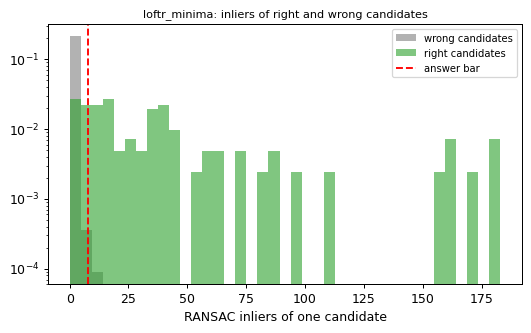

In [10]:
rows = []
for name in MATCHERS:
    wins = []
    zero = []
    auc_list = []
    inliers_right = []
    inliers_wrong = []
    for record in records:
        order, errors = ordered_errors(record, PRIMARY, BASE["K"], BASE["M"], BASE["layer"], BASE["weight"])
        inliers = fine[name][record["index"]]["inliers"][order]
        right = errors <= FOUND_SIGMA
        if not right.any():
            continue
        best_right = inliers[right].max()
        inliers_right.append(best_right)
        zero.append(best_right == 0)
        if (~right).any():
            best_wrong = inliers[~right].max()
            inliers_wrong.append(best_wrong)
            wins.append(best_right > best_wrong)
            good = inliers[right][:, None]
            bad = inliers[~right][None, :]
            auc_list.append(((good > bad).mean() + 0.5 * (good == bad).mean()))
    table = base[name]
    chosen_ok = table[table["chosen_right"] & table["answered"]]
    rows.append({"matcher": name, "photos with the target in M": len(inliers_right),
                 "right has most inliers": np.mean(wins), "right has 0 inliers": np.mean(zero),
                 "separation (right > wrong)": np.mean(auc_list),
                 "median best inliers, right": np.median(inliers_right), "median best inliers, wrong": np.median(inliers_wrong),
                 "median error after shift (sigma)": chosen_ok["err_sigma"].median() if len(chosen_ok) > 0 else np.nan,
                 "answered within 1 sigma": (chosen_ok["err_sigma"] <= STRICT_SIGMA).mean() if len(chosen_ok) > 0 else np.nan,
                 "seconds per photo (K_MAX candidates)": fine_seconds[name] / len(records)})
display(pd.DataFrame(rows).round(3))

fig, axes = plt.subplots(1, len(MATCHERS), figsize=(6 * len(MATCHERS), 3.8), squeeze=False)
for position, name in enumerate(MATCHERS):
    right_values = []
    wrong_values = []
    for record in records:
        order, errors = ordered_errors(record, PRIMARY, BASE["K"], BASE["M"], BASE["layer"], BASE["weight"])
        inliers = fine[name][record["index"]]["inliers"][order]
        right_values.extend(list(inliers[errors <= FOUND_SIGMA]))
        wrong_values.extend(list(inliers[errors > FOUND_SIGMA]))
    top = max(max(right_values + [1]), max(wrong_values + [1]))
    bins = np.linspace(0, top, 40)
    axes[0, position].hist(wrong_values, bins=bins, alpha=0.6, color="tab:gray", label="wrong candidates", density=True)
    axes[0, position].hist(right_values, bins=bins, alpha=0.6, color="tab:green", label="right candidates", density=True)
    axes[0, position].axvline(BASE["bar"], color="red", ls="--", label="answer bar")
    axes[0, position].set_yscale("log")
    axes[0, position].set_xlabel("RANSAC inliers of one candidate")
    axes[0, position].set_title("%s: inliers of right and wrong candidates" % name, fontsize=9)
    axes[0, position].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 6.5 Stage 5 · Decision: does it answer the right photos?

* **precision:** among the answered photos, the share within 4 sigma (and within 1 sigma).
* **answerable and answered:** among photos whose chosen position is within 4 sigma, the share that was answered.
* **points lost by skipping:** the points the skipped right answers would have earned.
* **points lost to wrong answers:** the points taken away by answers beyond 8 sigma (each −20).
* The sweep over the answer bar (and gamma and the rescue rule) is in Part 8; this part reports the baseline.

In [11]:
rows = []
for name in MATCHERS:
    table = base[name]
    answered = table[table["answered"]]
    answerable = table[table["err_sigma"] <= FOUND_SIGMA]
    skipped_right = table[(~table["answered"]) & (table["err_sigma"] <= FOUND_SIGMA)]
    wrong = table[table["points"] < 0]
    rows.append({"matcher": name, "answered": table["answered"].mean(),
                 "precision (4 sigma)": (answered["err_sigma"] <= FOUND_SIGMA).mean() if len(answered) > 0 else np.nan,
                 "precision (1 sigma)": (answered["err_sigma"] <= STRICT_SIGMA).mean() if len(answered) > 0 else np.nan,
                 "answerable photos": len(answerable), "answerable and answered": answerable["answered"].mean() if len(answerable) > 0 else np.nan,
                 "points lost by skipping (/photos)": float(skipped_right["would_earn"].sum()) / len(table),
                 "wrong answers": len(wrong), "points lost to wrong answers (/photos)": 20.0 * len(wrong) / len(table)})
display(pd.DataFrame(rows).round(3))
print("points lost are shown as points per photo: multiply by 6 for the effect on the score out of 60")

,matcher,answered,precision (4 sigma),precision (1 sigma),answerable photos,answerable and answered,points lost by skipping (/photos),wrong answers,points lost to wrong answers (/photos)
0,loftr_minima,0.71,0.986,0.915,85,0.824,1.46,1,0.2


points lost are shown as points per photo: multiply by 6 for the effect on the score out of 60


## 6.6 Stage 6 · End to end for the single query, per matcher

This is the old single-query chain (K = `K_BASE`, M = `M_BASE`). The same stages with the heading queries side by side are in Part 6.7.

The funnel follows each photo until the first stage that loses it. The **ceiling** next to each step is the score out of 60 if every photo that is still alive at that step were answered perfectly (+10) and the rest got 0: it shows how much each stage takes away.

matcher: loftr_minima | actual score 39.60 /60


,step,photos,share,lost here,ceiling score (/60)
0,all photos,100,1.00,0,60.0
1,target in the K peaks (coarse),88,0.88,12,52.8
2,target in the M sent to fine (DINO / M),88,0.88,0,52.8
3,right candidate chosen (fine),85,0.85,3,51.0
4,answered (decision),70,0.70,15,42.0
5,... and within 4 sigma,70,0.70,0,42.0
6,... and within 1 sigma,65,0.65,5,39.0


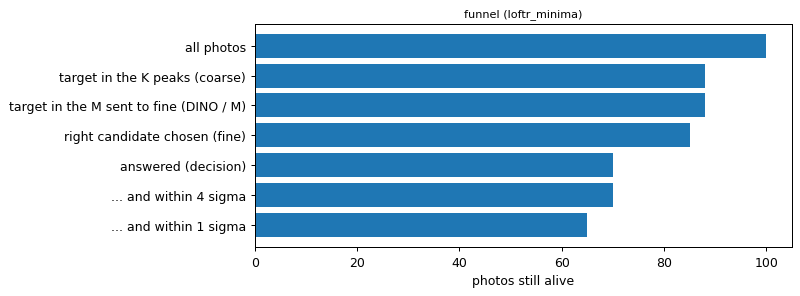

by flight height (loftr_minima):


,photos,score (/60),answered,target in K,target in M,right chosen | in M
height group,,,,,,
low,34.0,29.294,0.588,0.912,0.912,0.903
middle,33.0,42.909,0.727,0.818,0.818,1.000
high,33.0,46.909,0.818,0.909,0.909,1.000


In [12]:
for name in MATCHERS:
    table = base[name]
    total = len(table)
    answered_ok4 = table["answered"] & (table["err_sigma"] <= FOUND_SIGMA)
    answered_ok1 = table["answered"] & (table["err_sigma"] <= STRICT_SIGMA)
    steps = [("all photos", np.ones(total, dtype=bool)),
             ("target in the K peaks (coarse)", table["in_K"].to_numpy()),
             ("target in the M sent to fine (DINO / M)", (table["in_K"] & table["in_M"]).to_numpy()),
             ("right candidate chosen (fine)", (table["in_K"] & table["in_M"] & table["chosen_right"]).to_numpy()),
             ("answered (decision)", (table["in_K"] & table["in_M"] & table["chosen_right"] & table["answered"]).to_numpy()),
             ("... and within 4 sigma", answered_ok4.to_numpy()),
             ("... and within 1 sigma", answered_ok1.to_numpy())]
    rows = []
    previous = total
    for label, alive in steps:
        rows.append({"step": label, "photos": int(alive.sum()), "share": alive.mean(), "lost here": previous - int(alive.sum()),
                     "ceiling score (/60)": 60 * alive.mean()})
        previous = int(alive.sum())
    print("matcher:", name, "| actual score %.2f /60" % final_score(list(table["points"])))
    display(pd.DataFrame(rows).round(3))

    fig, axis = plt.subplots(figsize=(9, 3.4))
    axis.barh([row["step"] for row in rows][::-1], [row["photos"] for row in rows][::-1], color="tab:blue")
    axis.set_xlabel("photos still alive")
    axis.set_title("funnel (%s)" % name, fontsize=9)
    plt.tight_layout()
    plt.show()

main = base[MATCHERS[0]].copy()
main["height"] = [record_by_index[p]["height"] for p in main["photo"]]
main["height group"] = pd.qcut(main["height"].rank(method="first"), 3, labels=["low", "middle", "high"])
print("by flight height (%s):" % MATCHERS[0])
display(main.groupby("height group", observed=True).apply(lambda g: pd.Series({
    "photos": len(g), "score (/60)": final_score(list(g["points"])), "answered": g["answered"].mean(),
    "target in K": g["in_K"].mean(), "target in M": g["in_M"].mean(), "right chosen | in M": g["chosen_right"][g["in_M"]].mean() if g["in_M"].any() else np.nan})).round(3))

## 6.7 Heading queries: the same stages, every variant side by side

**Each photo is drawn once for every heading (and scale) in `HEADINGS` and `SCALE_FACTORS`**, and each drawing goes through coarse search, the DINO layer and the fine stage on its own (K = `HEADING_K`, M = `HEADING_M` per query, the coarse method is the one of this notebook). The answer is the candidate with most inliers (+ `GAMMA` times its DINO z-score) among **all** the candidates of the variant's queries.

A *variant* is a chosen subset of the queries (`HEADING_VARIANTS`), so every variant is scored from the same stored queries and nothing is run twice. The tables then ask the questions of stages 2 to 5 once per variant, next to the old single-query setting, on the same photos:

* **2 coarse:** a place within `FOUND_SIGMA` of the truth is among the K places of at least one query.
* **3 DINO:** it is still among the M places that were kept.
* **4 fine:** the right place is the one chosen (given that it was kept).
* **5 decision:** answered, how often right, wrong answers, points lost.

The points lost per stage figure shows where the 60 points go for each variant. Settings are not the same as the old setting in more than the headings (K and M differ), which is why the single-query chain with the heading settings is also given as a check.

In [13]:
if not RUN_HEADINGS:
    print("RUN_HEADINGS is False: Part 6.7 is skipped")
else:
    from heading_query_pipeline import HeadingQueryPipeline
    from train.checks.heading_results import variant_ids, query_rows, variant_rows, summarise as summarise_variant

    heading_pipeline = HeadingQueryPipeline.from_pipeline(pipeline, HEADINGS, SCALE_FACTORS, HEADING_K, HEADING_M, query_group=QUERY_GROUP)
    heading_pipeline.gamma = GAMMA                      # the base pipeline above was built with the defaults; the decision here uses this notebook's settings
    heading_pipeline.rescue_inliers = RESCUE_INLIERS
    heading_pipeline.rescue_z = RESCUE_Z
    heading_pipeline.dino_weight = WEIGHT_BASE
    for line in heading_pipeline.describe():
        print(line)

    heading_variants = {}
    for name, (variant_headings, variant_factors) in HEADING_VARIANTS.items():
        if all(h in HEADINGS for h in variant_headings) and all(f in SCALE_FACTORS for f in variant_factors):
            heading_variants[name] = variant_ids(heading_pipeline.queries, variant_headings, variant_factors)
        else:
            print("variant %r skipped: its headings or scale factors are not all among the queries" % name)
    print({name: len(ids) for name, ids in heading_variants.items()}, "queries per variant")

    heading_query_rows = {}       # photo -> rows of query_rows
    heading_found = {}            # photo -> the queries themselves (candidates, inliers, seconds per stage), read again in Parts 6.8 to 6.10
    heading_variant_rows = {}     # photo -> rows of variant_rows
    heading_failures = []
    heading_photos = [record["index"] for record in records]
    heading_start = time.time()
    for position, index in enumerate(heading_photos):
        item = test_set.items[index]
        truth = test_set.truths[index]
        sigma = test_set.sigmas[index]
        try:
            found = None
            for attempt in range(3):                    # the GPU may be shared with other notebooks: on a memory error free the cache, wait and try again
                try:
                    found = heading_pipeline.run_queries(item, test_set.priors[index])
                    break
                except torch.cuda.OutOfMemoryError:
                    torch.cuda.empty_cache()
                    time.sleep(5)
            if found is None:
                raise MemoryError("GPU out of memory three times in a row (close the other notebooks that use the GPU)")
            heading_found[index] = found
            heading_query_rows[index] = query_rows(found, truth, sigma, FOUND_SIGMA, MIN_INLIERS)
            heading_variant_rows[index] = variant_rows(heading_pipeline, found, heading_variants, truth, sigma, item["rel_height"], camera.fx, FOUND_SIGMA, MIN_INLIERS)
        except Exception as error:
            heading_failures.append(dict(photo=index, error="%s: %s" % (type(error).__name__, str(error)[:120])))
            print("photo %d failed: %s: %s" % (index, type(error).__name__, str(error)[:120]))
        if DEVICE == "cuda":
            torch.cuda.empty_cache()
        if (position + 1) % 10 == 0 or position + 1 == len(heading_photos):
            done = time.time() - heading_start
            print("heading queries: photo %d/%d | %.0f s so far | %.1f s per photo" % (position + 1, len(heading_photos), done, done / (position + 1)))
    print("%d photos done in %.0f s (%d failed)" % (len(heading_variant_rows), time.time() - heading_start, len(heading_failures)))
    assert len(heading_failures) <= 0.05 * len(heading_photos), "%d of %d photos failed: the tables below would describe only the photos that survived (see heading_failures)" % (len(heading_failures), len(heading_photos))

data: official | 379 photos available | zoom levels [3, 4, 5, 6, 7]
photos: official | map: new
coarse method: edge_zncc | maps: ['edge_zncc']
semantic layer: on (best K=50 -> M=10) | DINO in the decision: on (gamma 1.00, rescue (None, None))
fine matcher: loftr_minima | answer bar: 8 inliers | RANSAC 3.0 px | matcher confidence 0.21 | LoFTR coarse threshold 0.21, upscale 1.0 | border 0 px, margin 0 px
DINO order weight: 100.0 | projection overrides: none (settings.GEOMETRY)
batches: 5 LoFTR pairs and 25 DINO places per call
device: cuda
queries per photo: 27 (headings [-10.0, -7.5, -5.0, -2.5, 0.0, 2.5, 5.0, 7.5, 10.0], scale factors [0.95, 1.0, 1.05]); K and M are per query; 1 queries matched together
{'plain (heading 0)': 1, '3 headings (-5, 0, +5)': 3, '5 headings (step 5)': 5, '9 headings (step 2.5)': 9, 'standard 6 (-5, 0, +5 x 1.0, 1.05)': 6, 'wide 27 (9 headings x 3 scales)': 27} queries per variant
heading queries: photo 10/100 | 180 s so far | 18.0 s per photo
heading queries

In [14]:
# STAGE_TABLE_DONE
if not RUN_HEADINGS:
    print("RUN_HEADINGS is False: the variant tables are skipped")
else:
    heading_table = pd.concat([pd.DataFrame(heading_variant_rows[i]).assign(photo=i, height=test_set.items[i]["rel_height"]) for i in sorted(heading_variant_rows)], ignore_index=True)
    common = sorted(heading_variant_rows)
    baseline_part = base[MATCHERS[0]][base[MATCHERS[0]]["photo"].isin(common)].reset_index(drop=True)

    # the columns: the old single-query setting, then every heading variant, all on the same photos
    old_name = "old setting (1 query, K=%d, M=%d)" % (K_BASE, M_BASE)
    variant_frames = {old_name: baseline_part}
    for name in heading_variants:
        variant_frames[name] = heading_table[heading_table["variant"] == name].sort_values("photo").reset_index(drop=True)
    query_counts = {old_name: 1}
    for name in heading_variants:
        query_counts[name] = len(heading_variants[name])

    def stage_column(frame):
        total = len(frame)
        answered = frame[frame["answered"]]
        answerable = frame[frame["err_sigma"] <= FOUND_SIGMA]
        skipped_right = frame[(~frame["answered"]) & (frame["err_sigma"] <= FOUND_SIGMA)]
        wrong = frame[frame["points"] < 0]
        column = {}
        column["2 coarse: target in the K places"] = frame["in_K"].mean()
        column["3 DINO: target in the M kept"] = frame["in_M"].mean()
        column["3 DINO: target lost by keeping M of K"] = (frame["in_K"] & ~frame["in_M"]).mean()
        column["4 fine: right chosen, if target in M"] = frame["chosen_right"][frame["in_M"]].mean() if frame["in_M"].any() else np.nan
        column["5 decision: answered"] = frame["answered"].mean()
        column["5 decision: right when answered (4 sigma)"] = (answered["err_sigma"] <= FOUND_SIGMA).mean() if len(answered) > 0 else np.nan
        column["5 decision: answerable photos answered"] = answerable["answered"].mean() if len(answerable) > 0 else np.nan
        column["5 decision: wrong answers (-20)"] = len(wrong)
        column["points lost by skipping (/60)"] = 6.0 * float(skipped_right["would_earn"].sum()) / total
        column["points lost to wrong answers (/60)"] = 6.0 * 20.0 * len(wrong) / total
        column["score (/60)"] = final_score(list(frame["points"]))
        return column

    stage_table = pd.DataFrame({name: stage_column(frame) for name, frame in variant_frames.items()})
    stage_table.loc["queries per photo"] = pd.Series(query_counts)
    print("%d photos, the same for every column" % len(common))
    display(stage_table.round(3))

    # the old chain with the heading settings: it should agree with the plain query above, apart from a few matches the random fit decides differently
    same_setting = evaluate(dict(BASE, K=HEADING_K, M=HEADING_M), MATCHERS[0])
    same_setting = same_setting[same_setting["photo"].isin(common)].sort_values("photo").reset_index(drop=True)
    plain_frame = variant_frames["plain (heading 0)"]
    different = int(((same_setting["answered"] != plain_frame["answered"]) | ((same_setting["err_sigma"] - plain_frame["err_sigma"]).abs() > 0.05)).sum())
    print("check: single-query chain with K=%d, M=%d scores %.1f, the plain query here %.1f; %d of %d photos have another answer" % (
        HEADING_K, HEADING_M, final_score(list(same_setting["points"])), final_score(list(plain_frame["points"])), different, len(common)))

    height_group = pd.qcut(baseline_part.set_index("photo")["height"].rank(method="first"), 3, labels=["low", "middle", "high"])
    height_rows = []
    for label in ["low", "middle", "high"]:
        row = {"height group": label, "photos": int((height_group == label).sum())}
        for name, frame in variant_frames.items():
            row[name] = final_score(list(frame[frame["photo"].map(height_group).astype(str) == label]["points"]))
        height_rows.append(row)
    print("score (/60) by flight height, thirds of the photos")
    display(pd.DataFrame(height_rows).round(2))

100 photos, the same for every column


,"old setting (1 query, K=100, M=25)",plain (heading 0),"3 headings (-5, 0, +5)",5 headings (step 5),9 headings (step 2.5),"standard 6 (-5, 0, +5 x 1.0, 1.05)",wide 27 (9 headings x 3 scales)
2 coarse: target in the K places,0.880,0.880,0.990,1.000,1.000,0.990,1.000
3 DINO: target in the M kept,0.880,0.880,0.990,1.000,1.000,0.990,1.000
3 DINO: target lost by keeping M of K,0.000,0.000,0.000,0.000,0.000,0.000,0.000
"4 fine: right chosen, if target in M",0.966,0.977,0.929,0.900,0.920,0.949,0.930
5 decision: answered,0.710,0.700,0.770,0.800,0.860,0.810,0.900
5 decision: right when answered (4 sigma),0.986,1.000,1.000,1.000,1.000,1.000,0.989
5 decision: answerable photos answered,0.824,0.814,0.837,0.889,0.935,0.871,0.967
5 decision: wrong answers (-20),1.000,0.000,0.000,0.000,0.000,0.000,1.000
points lost by skipping (/60),8.760,9.360,8.280,5.760,3.600,6.960,1.800
points lost to wrong answers (/60),1.200,0.000,0.000,0.000,0.000,0.000,1.200


check: single-query chain with K=50, M=10 scores 40.8, the plain query here 40.8; 0 of 100 photos have another answer
score (/60) by flight height, thirds of the photos


,height group,photos,"old setting (1 query, K=100, M=25)",plain (heading 0),"3 headings (-5, 0, +5)",5 headings (step 5),9 headings (step 2.5),"standard 6 (-5, 0, +5 x 1.0, 1.05)",wide 27 (9 headings x 3 scales)
0,low,34,29.29,32.82,38.12,38.12,43.41,38.12,41.65
1,middle,33,42.91,42.91,47.64,53.09,56.73,53.82,59.27
2,high,33,46.91,46.91,48.73,48.73,49.09,49.82,51.64


points lost per stage (of 60), same 100 photos for every column


variant,"old setting (1 query, K=100, M=25)",plain (heading 0),"3 headings (-5, 0, +5)",5 headings (step 5),9 headings (step 2.5),"standard 6 (-5, 0, +5 x 1.0, 1.05)",wide 27 (9 headings x 3 scales)
step,,,,,,,
target in the K places (coarse),7.2,7.2,0.6,0.0,0.0,0.6,0.0
target in the M kept (DINO),0.0,0.0,0.0,0.0,0.0,0.0,0.0
right candidate chosen (fine),1.8,1.2,4.2,6.0,4.8,3.0,4.2
answered (decision),9.0,9.6,9.0,6.0,3.6,7.8,2.4
... and within 4 sigma,0.0,0.0,0.0,0.0,0.0,0.0,0.0
... and within 1 sigma,3.0,3.0,3.6,3.6,4.8,3.6,3.6


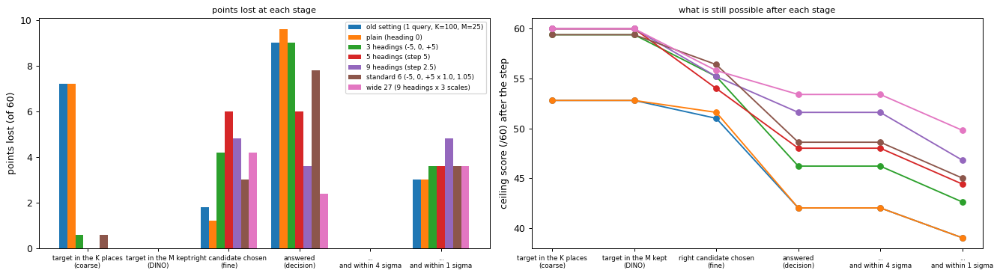

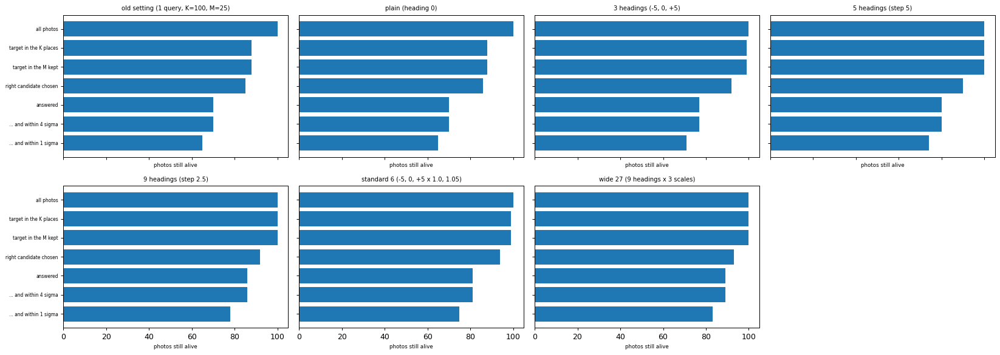

In [15]:
if RUN_HEADINGS:
    # points lost per stage, for every column of the table above: a step's "points lost" = 60 x (photos alive before - photos alive after) / photos,
    # so the losses add up to 60 - the score of the last step
    step_names = ["target in the K places (coarse)", "target in the M kept (DINO)", "right candidate chosen (fine)", "answered (decision)", "... and within 4 sigma", "... and within 1 sigma"]

    def alive_steps(frame):
        # photos alive after each step; a photo is alive only while every step before it holds
        in_k = frame["in_K"].to_numpy(dtype=bool)
        kept = in_k & frame["in_M"].to_numpy(dtype=bool)
        chosen = kept & frame["chosen_right"].to_numpy(dtype=bool)
        answered = chosen & frame["answered"].to_numpy(dtype=bool)
        within4 = answered & (frame["err_sigma"].to_numpy() <= FOUND_SIGMA)
        within1 = answered & (frame["err_sigma"].to_numpy() <= STRICT_SIGMA)
        return [in_k, kept, chosen, answered, within4, within1]

    stage_rows = []
    for variant, frame in variant_frames.items():
        steps = alive_steps(frame)
        previous = len(frame)
        for label, alive in zip(step_names, steps):
            stage_rows.append({"variant": variant, "step": label, "photos alive": int(alive.sum()), "points lost here": 60.0 * (previous - int(alive.sum())) / len(frame),
                               "ceiling score (/60)": 60.0 * alive.mean()})
            previous = int(alive.sum())
    stage_loss = pd.DataFrame(stage_rows)
    lost = stage_loss.pivot(index="step", columns="variant", values="points lost here").reindex(step_names)[list(variant_frames)]
    print("points lost per stage (of 60), same %d photos for every column" % len(common))
    display(lost.round(2))

    fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
    width = 0.8 / len(variant_frames)
    labels = [n.replace(" (", "\n(").replace(" and ", "\nand ") for n in step_names]
    for k, variant in enumerate(variant_frames):
        axes[0].bar(np.arange(len(step_names)) + k * width, lost[variant], width=width, label=variant)
        axes[1].plot(range(len(step_names)), stage_loss[stage_loss["variant"] == variant]["ceiling score (/60)"], marker="o", label=variant)
    axes[0].set_xticks(np.arange(len(step_names)) + width * (len(variant_frames) - 1) / 2)
    axes[0].set_xticklabels(labels, fontsize=7)
    axes[0].set_ylabel("points lost (of 60)")
    axes[0].set_title("points lost at each stage", fontsize=9)
    axes[0].legend(fontsize=7)
    axes[1].set_xticks(range(len(step_names)))
    axes[1].set_xticklabels(labels, fontsize=7)
    axes[1].set_ylabel("ceiling score (/60) after the step")
    axes[1].set_title("what is still possible after each stage", fontsize=9)
    plt.tight_layout()
    plt.show()

    # the same funnel as bars of photos still alive, one panel per variant (the shape of the funnel of Part 6.6)
    columns = 4
    rows_needed = (len(variant_frames) + columns - 1) // columns
    fig, axes = plt.subplots(rows_needed, columns, figsize=(4.6 * columns, 3.3 * rows_needed), sharex=True, squeeze=False)
    funnel_labels = ["all photos"] + [n.replace(" (coarse)", "").replace(" (DINO)", "").replace(" (fine)", "").replace(" (decision)", "") for n in step_names]
    for slot, (variant, frame) in enumerate(variant_frames.items()):
        axis = axes[slot // columns][slot % columns]
        alive_counts = [len(frame)] + [int(alive.sum()) for alive in alive_steps(frame)]
        axis.barh(funnel_labels[::-1], alive_counts[::-1], color="tab:blue")
        axis.set_title(variant, fontsize=8)
        axis.tick_params(axis="y", labelsize=6)
        if slot % columns != 0:
            axis.set_yticklabels([])
        axis.set_xlabel("photos still alive", fontsize=7)
    for slot in range(len(variant_frames), rows_needed * columns):
        axes[slot // columns][slot % columns].axis("off")
    plt.tight_layout()
    plt.show()


In [16]:
if RUN_HEADINGS:
    # paired bootstrap: the score of each variant minus the plain query's, same photos, 2000 resamples of the photos
    plain_name = "plain (heading 0)"
    points = {name: frame["points"].to_numpy() for name, frame in variant_frames.items()}
    rng = np.random.default_rng(SEED)
    count = len(points[plain_name])
    draws = rng.integers(0, count, size=(2000, count))
    rows = []
    for name in variant_frames:
        if name == plain_name:
            continue
        change = final_score(list(points[name])) - final_score(list(points[plain_name]))
        resampled = [final_score(list(points[name][d])) - final_score(list(points[plain_name][d])) for d in draws]
        low, high = np.percentile(resampled, [2.5, 97.5])
        rows.append({"variant": name, "change vs plain": change, "95% low": low, "95% high": high})
    display(pd.DataFrame(rows).round(2))

    # which heading finds the place: one query alone, for the plain scale
    query_table = pd.DataFrame([row for i in sorted(heading_query_rows) for row in heading_query_rows[i]])
    by_heading = query_table[query_table["scale_factor"] == 1.0].groupby("heading").agg(
        target_found=("target_found", "mean"), right_reaches_bar=("right_reaches_bar", "mean"), seconds=("seconds", "mean")).reset_index()
    display(by_heading.round(3))

,variant,change vs plain,95% low,95% high
0,"old setting (1 query, K=100, M=25)",-1.20,-3.60,0.00
1,"3 headings (-5, 0, +5)",3.96,1.20,7.20
2,5 headings (step 5),5.76,2.40,9.36
3,9 headings (step 2.5),8.88,4.92,13.32
4,"standard 6 (-5, 0, +5 x 1.0, 1.05)",6.36,3.12,9.84
5,wide 27 (9 headings x 3 scales),9.96,4.92,15.00


,heading,target_found,right_reaches_bar,seconds
0,-10.0,0.35,0.25,0.662
1,-7.5,0.63,0.48,0.661
2,-5.0,0.77,0.59,0.661
3,-2.5,0.91,0.70,0.662
4,0.0,0.88,0.70,0.662
5,2.5,0.81,0.72,0.663
6,5.0,0.70,0.61,0.662
7,7.5,0.52,0.37,0.661
8,10.0,0.37,0.23,0.661


## 6.8 Time: where do the seconds go?

Three tables, all measured on this computer (RTX 3050 laptop GPU, the Jetson is slower: the submitted code took 13 s per photo on average there, 4 to 5 s here).

* **One query, stage by stage.** Pass A and pass B measured each stage with the GPU finished before every clock reading. The first photo is left out because it pays for starting the GPU. The coarse search here is the fused one (`COARSE`, six maps), the heading queries use the cheap `edge_zncc`, so their coarse step is much faster.
* **What K and M cost.** The DINO step was measured on `K_MAX` places and the fine step on `K_MAX` places, so the time of a smaller K or M is that time times K / `K_MAX` or M / `K_MAX`. This is an estimate, the matcher cost per place is almost constant.
* **One query of the heading pipeline** (`edge_zncc`, K = `HEADING_K`, M = `HEADING_M`), by stage, as it runs in the final pipeline.

one query of this notebook's baseline (edge_zncc, K=100, M=25, loftr_minima), 99 photos without the warm-up photo


,stage,mean (s),median (s),95th percentile (s),max (s),share of the total
0,render,0.007,0.007,0.008,0.010,0.005
1,maps,0.194,0.199,0.474,0.501,0.151
2,coarse,0.001,0.001,0.002,0.003,0.001
3,semantic,0.207,0.208,0.229,0.242,0.162
4,fine,0.874,0.887,0.893,0.949,0.681
5,total,1.282,1.302,1.592,1.628,1.000


seconds per photo for one query at each K (rows) and M (columns); 0.201 s fixed, 0.0021 s per DINO place, 0.0349 s per fine place


,M=1,M=3,M=5,M=10,M=15,M=25,M=50
K,,,,,,,
5,0.25,0.32,0.39,NaN,NaN,NaN,NaN
10,0.26,0.33,0.40,0.57,NaN,NaN,NaN
25,0.29,0.36,0.43,0.60,0.78,1.13,NaN
50,0.34,0.41,0.48,0.65,0.83,1.18,2.05
100,0.44,0.51,0.58,0.76,0.93,1.28,2.16


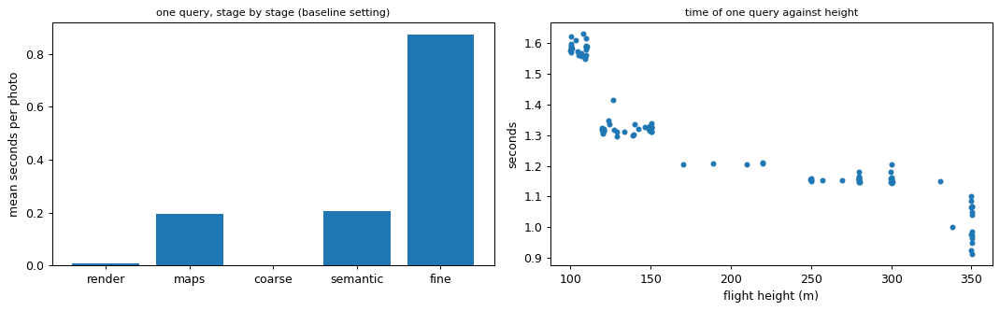

In [17]:
stage_labels = ["render", "maps", "coarse", "semantic", "fine"]
warm_up_index = records[0]["index"]
stage_seconds = {label: [] for label in stage_labels}
for record in records:
    if record["index"] == warm_up_index:
        continue
    method_seconds = record["methods"][PRIMARY]["seconds"]
    stage_seconds["render"].append(record["seconds"]["render"])
    stage_seconds["maps"].append(record["seconds"]["maps"])
    stage_seconds["coarse"].append(method_seconds["coarse"])
    stage_seconds["semantic"].append(method_seconds["semantic"] * K_BASE / K_MAX)     # DINO time for K_BASE places
    stage_seconds["fine"].append(fine_photo_seconds[MATCHERS[0]][record["index"]] * M_BASE / K_MAX)   # fine time for M_BASE places
baseline_seconds = np.zeros(len(stage_seconds["render"]))
for label in stage_labels:
    baseline_seconds += np.array(stage_seconds[label])

time_rows = []
for label in stage_labels:
    values = np.array(stage_seconds[label])
    time_rows.append({"stage": label, "mean (s)": values.mean(), "median (s)": np.median(values), "95th percentile (s)": np.percentile(values, 95),
                      "max (s)": values.max(), "share of the total": values.sum() / baseline_seconds.sum()})
time_rows.append({"stage": "total", "mean (s)": baseline_seconds.mean(), "median (s)": np.median(baseline_seconds),
                  "95th percentile (s)": np.percentile(baseline_seconds, 95), "max (s)": baseline_seconds.max(), "share of the total": 1.0})
stage_time_table = pd.DataFrame(time_rows)
print("one query of this notebook's baseline (%s, K=%d, M=%d, %s), %d photos without the warm-up photo" % (COARSE, K_BASE, M_BASE, MATCHERS[0], len(baseline_seconds)))
display(stage_time_table.round(3))

# what the choice of K and M costs per photo, from the measured seconds per place
fixed_seconds = np.mean(stage_seconds["render"]) + np.mean(stage_seconds["maps"]) + np.mean(stage_seconds["coarse"])
dino_per_place = np.mean([r["methods"][PRIMARY]["seconds"]["semantic"] for r in records if r["index"] != warm_up_index]) / K_MAX
fine_per_place = np.mean([fine_photo_seconds[MATCHERS[0]][r["index"]] for r in records if r["index"] != warm_up_index]) / K_MAX
cost_rows = []
for k_value in K_LIST:
    row = {"K": k_value}
    for m_value in M_LIST:
        if m_value <= k_value:
            row["M=%d" % m_value] = fixed_seconds + dino_per_place * k_value + fine_per_place * m_value
        else:
            row["M=%d" % m_value] = np.nan
    cost_rows.append(row)
print("seconds per photo for one query at each K (rows) and M (columns); %.3f s fixed, %.4f s per DINO place, %.4f s per fine place" % (fixed_seconds, dino_per_place, fine_per_place))
cost_table = pd.DataFrame(cost_rows).set_index("K")
display(cost_table.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].bar(stage_labels, [np.mean(stage_seconds[label]) for label in stage_labels])
axes[0].set_ylabel("mean seconds per photo")
axes[0].set_title("one query, stage by stage (baseline setting)", fontsize=9)
heights_used = [r["height"] for r in records if r["index"] != warm_up_index]
axes[1].scatter(heights_used, baseline_seconds, s=14)
axes[1].set_xlabel("flight height (m)")
axes[1].set_ylabel("seconds")
axes[1].set_title("time of one query against height", fontsize=9)
plt.tight_layout()
plt.show()

In [18]:
if not RUN_HEADINGS:
    print("RUN_HEADINGS is False: the time of the heading queries is skipped")
else:
    # every query of every photo, by stage (these are the queries of Part 6.7: edge_zncc, K = HEADING_K, M = HEADING_M)
    query_stage_rows = []
    for index in sorted(heading_found):
        for query in heading_found[index]["queries"]:
            row = dict(photo=index, query=query["id"], heading=query["heading"], scale_factor=query["scale_factor"])
            total = 0.0
            for label in stage_labels:
                row[label] = query["seconds"][label]
                total += query["seconds"][label]
            row["total"] = total
            query_stage_rows.append(row)
    query_stage_table = pd.DataFrame(query_stage_rows)
    first_photo = query_stage_table["photo"].min()
    steady = query_stage_table[query_stage_table["photo"] != first_photo]      # the first photo pays for starting the GPU
    summary = steady[stage_labels + ["total"]].describe(percentiles=[0.5, 0.95]).T[["mean", "50%", "95%", "max"]]
    summary.columns = ["mean (s)", "median (s)", "95th percentile (s)", "max (s)"]
    summary["share of the query"] = steady[stage_labels + ["total"]].sum() / steady["total"].sum()
    print("one heading query (%s, K=%d, M=%d), %d queries" % (PRIMARY, HEADING_K, HEADING_M, len(steady)))
    display(summary.round(3))
    by_scale = steady.groupby("scale_factor")["total"].agg(["mean", "count"]).round(3)
    print("seconds per query by scale factor (the queries are drawn the same way, so the cost should not depend on it)")
    display(by_scale)

one heading query (edge_zncc, K=50, M=10), 2673 queries


,mean (s),median (s),95th percentile (s),max (s),share of the query
render,0.006,0.006,0.007,0.016,0.009
maps,0.190,0.198,0.466,0.485,0.289
coarse,0.001,0.001,0.002,0.003,0.001
semantic,0.107,0.106,0.117,0.132,0.162
fine,0.355,0.355,0.359,0.364,0.539
total,0.659,0.667,0.944,0.967,1.000


seconds per query by scale factor (the queries are drawn the same way, so the cost should not depend on it)


,mean,count
scale_factor,,
0.95,0.659,891
1.00,0.659,891
1.05,0.659,891


## 6.9 Decision steps: the bar, query agreement, escalation

This part replays the decision of `agreement_query_pipeline.py` on the stored queries of Part 6.7, so no matcher runs again. For each photo:

1. **Bar.** The 6 standard queries are pooled; the chosen place is answered when it has at least `MIN_INLIERS` inliers.
2. **Agreement.** Otherwise it is answered when at least `MIN_AGREE` of the 6 queries each found a place within `AGREE_RADIUS_SIGMA` sigma of the chosen place (each with at least `AGREE_QUERY_INLIERS` inliers).
3. **Escalation.** A photo still skipped is decided again over **all** the queries of Part 6.7 (27: the 6 already run are reused) and answered only with at least `ESCALATION_MIN_INLIERS` inliers. Agreement is not used here: queries 2.5 degrees apart see almost the same picture and land on the same false place together.

The time of a photo is the sum of the seconds of the queries it needed: 6 queries, or all 27 when it was escalated. A photo that is only answered at the bar by the standard queries costs 6.

4. **Inflation guard (stress test, last rows of the sweep).** If a camera or a map gave every candidate more inliers, false places would reach the bars. The sweep multiplies every stored inlier count by `INFLATION_FACTORS` and decides each photo twice, without and with the guard of `inflation_guard_pipeline.py`: the running mean of the inliers of the wrong places (more than 4 sigma from the answer, from the 6 standard queries) is compared with `GUARD_PRIOR`, and above `GUARD_DEAD_ZONE` times the prior the bar, the agreement floor and the escalation bar are multiplied by that ratio. At factor 1 the guard must change nothing.

**Read the sweep with care.** The bars and radii were chosen on development photos in Test_Iteration_3. Trust a setting only when the wrong answers stay at 0 over a flat range of values, not at one row.

In [19]:
if not RUN_HEADINGS:
    print("RUN_HEADINGS is False: Part 6.9 is skipped")
else:
    from semantic_rerank.agreement import query_agreement
    from inflation_guard_pipeline import far_level, guard_factor_from_level

    standard_ids = heading_variants[STANDARD_NAME]
    wide_ids = heading_variants[WIDE_NAME]

    def seconds_of(queries, ids):
        total = 0.0
        for query_id in ids:
            total += sum(queries[query_id]["seconds"].values())
        return total

    def inflate(queries, factor):
        # the same queries with every inlier count multiplied by factor (a sharper camera or a looser matcher)
        if factor == 1.0:
            return queries
        changed = []
        for query in queries:
            copy = dict(query)
            copy["stage2"] = dict(query["stage2"])
            copy["stage2"]["inliers"] = np.asarray(query["stage2"]["inliers"], dtype=float) * factor
            changed.append(copy)
        return changed

    def guard_factors(inflation):
        # the guard's factor for every photo, in photo order, from the running mean of the far-candidate level (as InflationGuardPipeline does it)
        factors = {}
        level_sum = 0.0
        photo_count = 0
        for index in sorted(heading_found):
            queries = inflate(heading_found[index]["queries"], inflation)
            answer = heading_pipeline.answer_for(queries, standard_ids)
            level_sum += far_level(queries, standard_ids, answer["x"], answer["y"], test_set.sigmas[index])
            photo_count += 1
            running = (GUARD_PRIOR_WEIGHT * GUARD_PRIOR + level_sum) / (GUARD_PRIOR_WEIGHT + photo_count)
            factors[index] = guard_factor_from_level(running, GUARD_PRIOR, GUARD_DEAD_ZONE)
        return factors

    def decide_photo(index, min_agree, radius_sigma, escalation_bar, inflation=1.0, guard_factor=1.0):
        # one photo through the three steps; returns the row of the table. inflation and guard_factor are for the stress test of the sweep (1.0 = as measured)
        queries = inflate(heading_found[index]["queries"], inflation)
        bar = int(round(MIN_INLIERS * guard_factor))
        agree_floor = int(round(AGREE_QUERY_INLIERS * guard_factor))
        escalation_bar = int(round(escalation_bar * guard_factor))
        sigma = test_set.sigmas[index]
        truth = test_set.truths[index]
        height = test_set.items[index]["rel_height"]

        answer = heading_pipeline.answer_for(queries, standard_ids)
        agreement = query_agreement(queries, standard_ids, answer["x"], answer["y"], radius_sigma * sigma, agree_floor)
        step = "skip"
        if answer["inliers"] >= bar:
            step = "bar"
        elif agreement >= min_agree:
            step = "agreement"
        used_ids = standard_ids
        if step == "skip":
            answer = heading_pipeline.answer_for(queries, wide_ids)
            used_ids = wide_ids
            if answer["inliers"] >= escalation_bar:
                step = "escalation"

        error_m = math.hypot(answer["x"] - truth[0], answer["y"] - truth[1])
        earned = points_for_error(error_m, height, camera.fx)
        answered = step != "skip"
        points = 0
        if answered:
            points = earned
        return dict(photo=index, height=height, step=step, answered=answered, inliers=answer["inliers"], agreement=agreement, err_sigma=error_m / sigma,
                    points=points, n_queries=len(used_ids), seconds=seconds_of(queries, used_ids), standard_seconds=seconds_of(queries, standard_ids))

    decision_rows = []
    for index in sorted(heading_found):
        decision_rows.append(decide_photo(index, MIN_AGREE, AGREE_RADIUS_SIGMA, ESCALATION_MIN_INLIERS))
    decision_table = pd.DataFrame(decision_rows)

    step_rows = []
    for step in ["bar", "agreement", "escalation", "skip"]:
        part = decision_table[decision_table["step"] == step]
        row = {"step": step, "photos": len(part), "wrong answers": int((part["points"] < 0).sum()), "points": int(part["points"].sum())}
        if len(part) > 0:
            row["mean queries"] = part["n_queries"].mean()
            row["mean seconds"] = part["seconds"].mean()
        else:
            row["mean queries"] = np.nan
            row["mean seconds"] = np.nan
        step_rows.append(row)
    print("which step answered each of the %d photos" % len(decision_table))
    display(pd.DataFrame(step_rows).round(2))

    # the score built up step by step: a photo answered by a later step counts as skipped in the earlier rows
    build_rows = []
    allowed_steps = [("bar only (6 queries)", ["bar"]), ("+ agreement", ["bar", "agreement"]), ("+ escalation (27 queries)", ["bar", "agreement", "escalation"])]
    half = len(decision_table) // 2
    for label, allowed in allowed_steps:
        points_list = []
        seconds_list = []
        for position in range(len(decision_table)):
            row = decision_table.iloc[position]
            if row["step"] in allowed:
                points_list.append(int(row["points"]))
            else:
                points_list.append(0)
            if "escalation" in allowed:
                seconds_list.append(row["seconds"])
            else:
                seconds_list.append(row["standard_seconds"])
        wrong = 0
        answered = 0
        for position in range(len(decision_table)):
            if decision_table["step"].iloc[position] in allowed:
                answered += 1
                if points_list[position] < 0:
                    wrong += 1
        build_rows.append({"answers allowed from": label, "score (/60)": final_score(points_list), "first half": final_score(points_list[:half]),
                           "second half": final_score(points_list[half:]), "answered": answered / len(decision_table), "wrong answers": wrong,
                           "seconds per photo": float(np.mean(seconds_list))})
    build_table = pd.DataFrame(build_rows)
    display(build_table.round(3))

which step answered each of the 100 photos


,step,photos,wrong answers,points,mean queries,mean seconds
0,bar,81,0,786,6.0,3.87
1,agreement,6,0,60,6.0,4.37
2,escalation,3,0,30,27.0,16.67
3,skip,10,0,0,27.0,20.87


,answers allowed from,score (/60),first half,second half,answered,wrong answers,seconds per photo
0,bar only (6 queries),47.16,47.76,46.56,0.81,0,3.970
1,+ agreement,50.76,51.36,50.16,0.87,0,3.970
2,+ escalation (27 queries),52.56,52.56,52.56,0.90,0,5.982


In [20]:
if RUN_HEADINGS:
    # sweep: the escalation bar, then the agreement radius and the number of agreeing queries (same stored queries, nothing is run again)
    sweep_rows = []
    for inflation in INFLATION_FACTORS:
        for with_guard in (False, True):
            factors = {}
            if with_guard:
                factors = guard_factors(inflation)
            rows = []
            for index in sorted(heading_found):
                rows.append(decide_photo(index, MIN_AGREE, AGREE_RADIUS_SIGMA, ESCALATION_MIN_INLIERS, inflation, factors.get(index, 1.0)))
            part = pd.DataFrame(rows)
            label = "x%.2f, guard on" % inflation if with_guard else "x%.2f, guard off" % inflation
            sweep_rows.append({"what": "inliers multiplied by a factor", "value": label, "score (/60)": final_score(list(part["points"])), "wrong answers": int((part["points"] < 0).sum()),
                               "answered": part["answered"].mean(), "seconds per photo": part["seconds"].mean()})
    for bar in ESCALATION_BARS:
        rows = []
        for index in sorted(heading_found):
            rows.append(decide_photo(index, MIN_AGREE, AGREE_RADIUS_SIGMA, bar))
        part = pd.DataFrame(rows)
        sweep_rows.append({"what": "escalation bar", "value": bar, "score (/60)": final_score(list(part["points"])), "wrong answers": int((part["points"] < 0).sum()),
                           "answered": part["answered"].mean(), "seconds per photo": part["seconds"].mean()})
    for radius in AGREE_RADII:
        for minimum in AGREE_MINIMUMS:
            rows = []
            for index in sorted(heading_found):
                rows.append(decide_photo(index, minimum, radius, ESCALATION_MIN_INLIERS))
            part = pd.DataFrame(rows)
            sweep_rows.append({"what": "agreement radius (sigma), queries", "value": "%.1f, %d" % (radius, minimum), "score (/60)": final_score(list(part["points"])),
                               "wrong answers": int((part["points"] < 0).sum()), "answered": part["answered"].mean(), "seconds per photo": part["seconds"].mean()})
    decision_sweep = pd.DataFrame(sweep_rows)
    display(decision_sweep.round(3))

    # paired bootstrap of each step against the bar-only decision, same photos, 2000 resamples
    points_by_label = {}
    for label, allowed in allowed_steps:
        values = []
        for position in range(len(decision_table)):
            if decision_table["step"].iloc[position] in allowed:
                values.append(int(decision_table["points"].iloc[position]))
            else:
                values.append(0)
        points_by_label[label] = np.array(values)
    rng = np.random.default_rng(SEED)
    count = len(decision_table)
    draws = rng.integers(0, count, size=(2000, count))
    bootstrap_rows = []
    bar_only = points_by_label[allowed_steps[0][0]]
    for label, allowed in allowed_steps[1:]:
        change = final_score(list(points_by_label[label])) - final_score(list(bar_only))
        resampled = []
        for draw in draws:
            resampled.append(final_score(list(points_by_label[label][draw])) - final_score(list(bar_only[draw])))
        low, high = np.percentile(resampled, [2.5, 97.5])
        bootstrap_rows.append({"step": label, "change vs bar only": change, "95% low": low, "95% high": high})
    display(pd.DataFrame(bootstrap_rows).round(2))

,what,value,score (/60),wrong answers,answered,seconds per photo
0,escalation bar,8,51.36,1,0.91,5.982
1,escalation bar,9,52.56,0,0.90,5.982
2,escalation bar,10,52.56,0,0.90,5.982
3,escalation bar,11,52.56,0,0.90,5.982
4,escalation bar,12,52.56,0,0.90,5.982
5,escalation bar,13,52.56,0,0.90,5.982
6,"agreement radius (sigma), queries","0.5, 2",51.36,0,0.88,6.365
7,"agreement radius (sigma), queries","0.5, 3",51.12,0,0.88,6.754
8,"agreement radius (sigma), queries","1.0, 2",52.56,0,0.90,5.982
9,"agreement radius (sigma), queries","1.0, 3",51.12,0,0.88,6.416


,step,change vs bar only,95% low,95% high
0,+ agreement,3.6,1.2,6.6
1,+ escalation (27 queries),5.4,2.4,9.0


points lost per stage (of 60), same 100 photos for every column


variant,"old setting (1 query, K=100, M=25)",plain (heading 0),standard 6 bar only (6 queries),standard 6 + agreement,standard 6 + escalation (27 queries)
step,,,,,
target in the K places (coarse),7.2,7.2,0.6,0.6,0.0
target in the M kept (DINO),0.0,0.0,0.0,0.0,0.0
right candidate chosen (fine),1.8,1.2,3.0,3.0,4.2
answered (decision),9.0,9.6,7.8,4.2,1.8
... and within 4 sigma,0.0,0.0,0.0,0.0,0.0
... and within 1 sigma,3.0,3.0,3.6,3.6,3.6


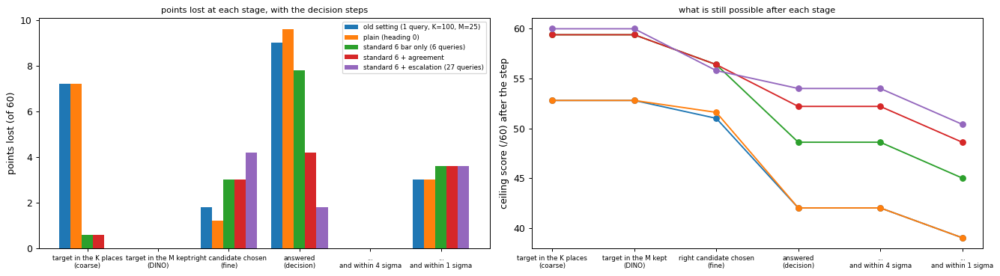

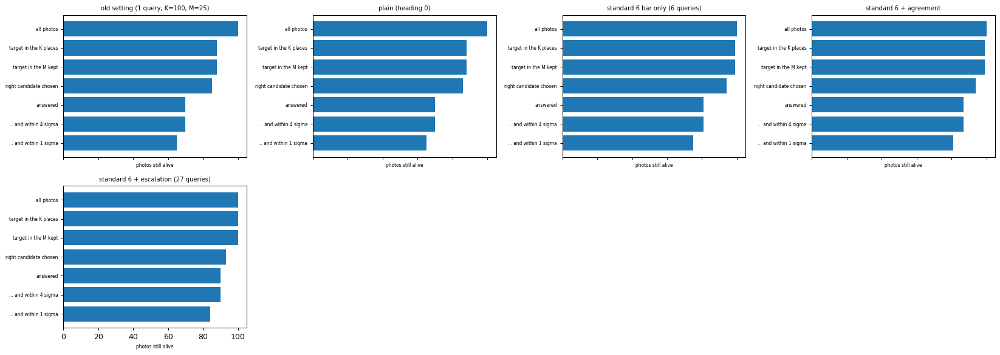

In [29]:
if RUN_HEADINGS:
    # the funnel of Part 6.7 for the decision steps: bar only, + agreement, + escalation, built from the stored queries and decision_table (nothing is run again)
    # a photo answered by the bar or by agreement uses the 6 standard queries; an escalated photo uses all 27, so its coarse / DINO / fine columns come from the wide variant
    standard_frame = variant_frames[STANDARD_NAME].set_index("photo")
    wide_frame = variant_frames[WIDE_NAME].set_index("photo")
    decided = decision_table.set_index("photo")

    def decision_frame(allowed):
        rows = []
        for photo, decision in decided.iterrows():
            escalated = ("escalation" in allowed) and decision["step"] in ("escalation", "skip")
            source = wide_frame if escalated else standard_frame
            row = source.loc[photo, ["in_K", "in_M", "chosen_right"]].to_dict()
            row["photo"] = photo
            row["answered"] = decision["step"] in allowed
            row["err_sigma"] = decision["err_sigma"]
            rows.append(row)
        return pd.DataFrame(rows)

    decision_frames = {old_name: variant_frames[old_name], "plain (heading 0)": variant_frames["plain (heading 0)"]}
    for label, allowed in allowed_steps:
        decision_frames["standard 6 " + label] = decision_frame(allowed)

    decision_loss = []
    for variant, frame in decision_frames.items():
        previous = len(frame)
        for label, alive in zip(step_names, alive_steps(frame)):
            decision_loss.append({"variant": variant, "step": label, "points lost here": 60.0 * (previous - int(alive.sum())) / len(frame), "ceiling score (/60)": 60.0 * alive.mean()})
            previous = int(alive.sum())
    decision_loss = pd.DataFrame(decision_loss)
    decision_lost = decision_loss.pivot(index="step", columns="variant", values="points lost here").reindex(step_names)[list(decision_frames)]
    print("points lost per stage (of 60), same %d photos for every column" % len(decided))
    display(decision_lost.round(2))

    fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
    width = 0.8 / len(decision_frames)
    labels = [n.replace(" (", "\n(").replace(" and ", "\nand ") for n in step_names]
    for k, variant in enumerate(decision_frames):
        axes[0].bar(np.arange(len(step_names)) + k * width, decision_lost[variant], width=width, label=variant)
        axes[1].plot(range(len(step_names)), decision_loss[decision_loss["variant"] == variant]["ceiling score (/60)"], marker="o", label=variant)
    axes[0].set_xticks(np.arange(len(step_names)) + width * (len(decision_frames) - 1) / 2)
    axes[0].set_xticklabels(labels, fontsize=7)
    axes[0].set_ylabel("points lost (of 60)")
    axes[0].set_title("points lost at each stage, with the decision steps", fontsize=9)
    axes[0].legend(fontsize=7)
    axes[1].set_xticks(range(len(step_names)))
    axes[1].set_xticklabels(labels, fontsize=7)
    axes[1].set_ylabel("ceiling score (/60) after the step")
    axes[1].set_title("what is still possible after each stage", fontsize=9)
    plt.tight_layout()
    plt.show()

    # photos still alive, one panel per column
    columns = 4
    rows_needed = (len(decision_frames) + columns - 1) // columns
    fig, axes = plt.subplots(rows_needed, columns, figsize=(4.6 * columns, 3.3 * rows_needed), sharex=True, squeeze=False)
    for axis in axes.ravel():
        axis.set_visible(False)
    for slot, (variant, frame) in enumerate(decision_frames.items()):
        axis = axes[slot // columns][slot % columns]
        axis.set_visible(True)
        alive_counts = [len(frame)] + [int(alive.sum()) for alive in alive_steps(frame)]
        axis.barh(funnel_labels[::-1], alive_counts[::-1])
        axis.set_title(variant, fontsize=8)
        axis.tick_params(axis="y", labelsize=6)
        axis.set_xlabel("photos still alive", fontsize=6)
    plt.tight_layout()
    plt.show()


## 6.10 All phases side by side: score, wrong answers, time

One table from the single query of the top of this notebook to the full decision, on the same photos. `queries` is the mean number of queries a photo needed. `seconds per photo` is measured on this computer; `over 22 s` and `over 30 s` count the photos that the Jetson time budget and the 30 s limit would cut, **if this computer were as slow as the Jetson**, so read them as a way to compare phases, not as flight numbers (on the Jetson the submitted code took 13 s on average, about three times this computer's time).

The first row is the stage evaluation's own baseline (the coarse search of `COARSE`, K = `K_BASE`, M = `M_BASE`, one query, no heading change): its seconds come from Part 6.8. The next rows are the heading variants of Part 6.7, then the decision steps of Part 6.9.

,phase,queries,score (/60),wrong answers,answered,seconds per photo,over 22 s,over 30 s
0,1 query (this notebook's baseline),1.00,39.60,1,0.71,1.282,0,0
1,"plain (heading 0), answer at the bar",1.00,40.80,0,0.70,0.662,0,0
2,"3 headings (-5, 0, +5), answer at the bar",3.00,44.76,0,0.77,1.985,0,0
3,"5 headings (step 5), answer at the bar",5.00,46.56,0,0.80,3.308,0,0
4,"9 headings (step 2.5), answer at the bar",9.00,49.68,0,0.86,5.955,0,0
5,"standard 6 (-5, 0, +5 x 1.0, 1.05), answer at ...",6.00,47.16,0,0.81,3.970,0,0
6,"wide 27 (9 headings x 3 scales), answer at the...",27.00,50.76,1,0.90,17.868,23,0
7,standard 6 + agreement,6.00,50.76,0,0.87,3.970,0,0
8,standard 6 + escalation (27 queries),8.73,52.56,0,0.90,5.982,5,0


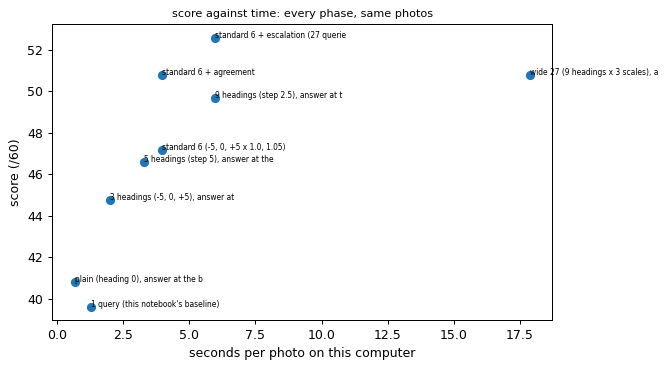

In [21]:
if not RUN_HEADINGS:
    print("RUN_HEADINGS is False: Part 6.10 is skipped")
else:
    def over(values, limit):
        count = 0
        for value in values:
            if value > limit:
                count += 1
        return count

    phase_rows = []
    reference = summarise(baseline_part)
    phase_rows.append({"phase": "1 query (this notebook's baseline)", "queries": 1.0, "score (/60)": reference["score (/60)"], "wrong answers": reference["wrong answers"],
                       "answered": reference["answered"], "seconds per photo": float(np.mean(baseline_seconds)),
                       "over %d s" % TIME_BUDGET_S: over(baseline_seconds, TIME_BUDGET_S), "over %d s" % TIME_LIMIT_S: over(baseline_seconds, TIME_LIMIT_S)})
    for name in heading_variants:
        part = heading_table[heading_table["variant"] == name].sort_values("photo")
        values = summarise_variant(part, FOUND_SIGMA)
        phase_rows.append({"phase": name + ", answer at the bar", "queries": float(part["n_queries"].mean()), "score (/60)": values["score (/60)"],
                           "wrong answers": values["wrong answers"], "answered": values["answered"], "seconds per photo": values["seconds per photo"],
                           "over %d s" % TIME_BUDGET_S: over(part["seconds"], TIME_BUDGET_S), "over %d s" % TIME_LIMIT_S: over(part["seconds"], TIME_LIMIT_S)})
    for label, allowed in allowed_steps[1:]:
        points_list = list(points_by_label[label])
        seconds_list = []
        queries_list = []
        for position in range(len(decision_table)):
            row = decision_table.iloc[position]
            if "escalation" in allowed:
                seconds_list.append(row["seconds"])
                queries_list.append(row["n_queries"])
            else:
                seconds_list.append(row["standard_seconds"])
                queries_list.append(len(standard_ids))
        wrong = 0
        answered = 0
        for position in range(len(decision_table)):
            if decision_table["step"].iloc[position] in allowed:
                answered += 1
                if points_list[position] < 0:
                    wrong += 1
        phase_rows.append({"phase": "standard 6 " + label, "queries": float(np.mean(queries_list)), "score (/60)": final_score(points_list), "wrong answers": wrong,
                           "answered": answered / len(decision_table), "seconds per photo": float(np.mean(seconds_list)),
                           "over %d s" % TIME_BUDGET_S: over(seconds_list, TIME_BUDGET_S), "over %d s" % TIME_LIMIT_S: over(seconds_list, TIME_LIMIT_S)})
    phase_table = pd.DataFrame(phase_rows)
    display(phase_table.round(3))

    fig, axis = plt.subplots(figsize=(7.5, 4.2))
    axis.scatter(phase_table["seconds per photo"], phase_table["score (/60)"], s=40)
    for position in range(len(phase_table)):
        axis.annotate(phase_table["phase"].iloc[position][:34], (phase_table["seconds per photo"].iloc[position], phase_table["score (/60)"].iloc[position]), fontsize=6)
    axis.set_xlabel("seconds per photo on this computer")
    axis.set_ylabel("score (/60)")
    axis.set_title("score against time: every phase, same photos", fontsize=9)
    plt.tight_layout()
    plt.show()

# Part 7 · Image processing sample: render and map agreement

The photos where the score maps see the target least clearly (lowest z near the truth, from 6.1) and the photos where they see it best. For each: the north-up canvas, the true map tile and the canvas laid over it. This is the quickest check of the geometry and the cleaned thermal photo.

lowest z near the truth (the target is hardest to see in the map)


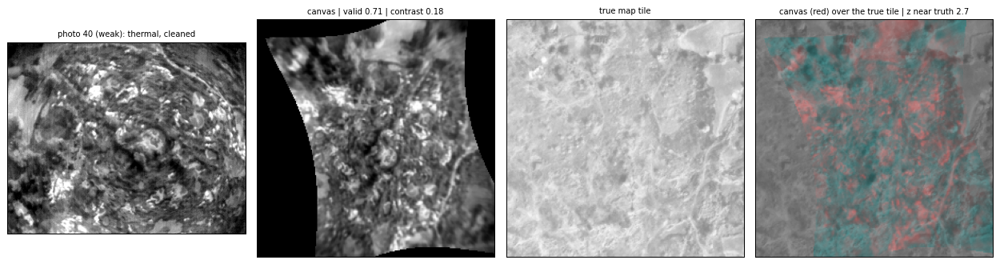

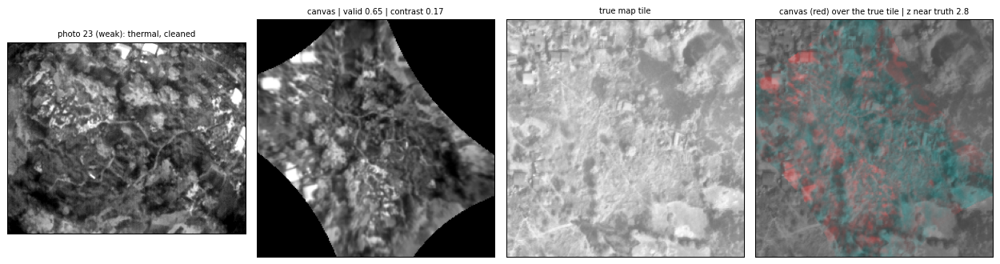

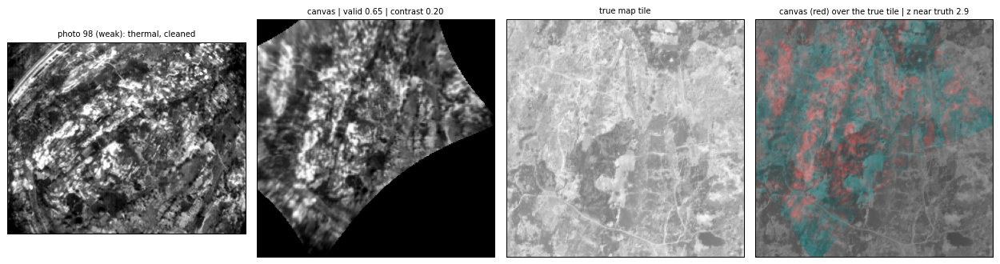

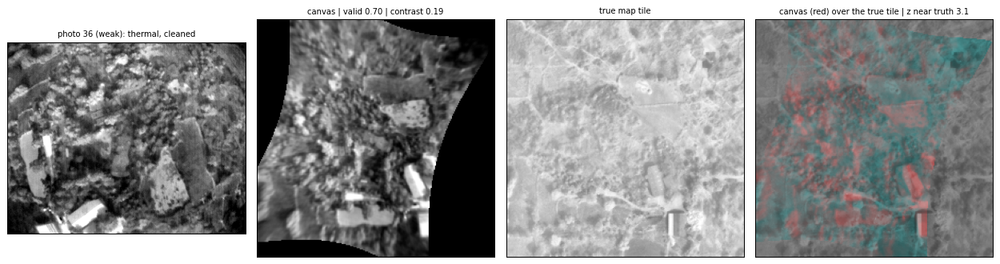

highest z near the truth


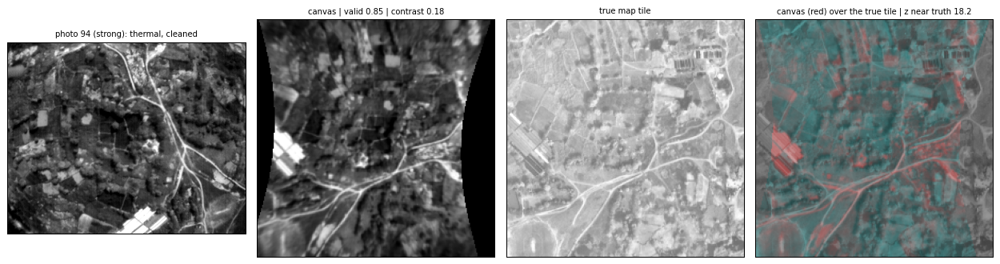

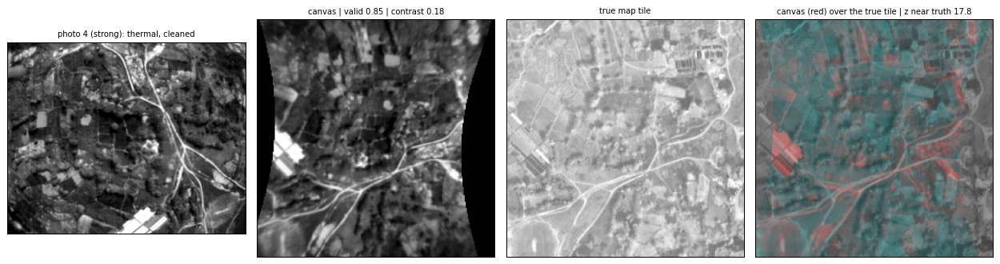

In [22]:
def show(axis, picture, title="", cmap="gray", vmin=0, vmax=1):
    axis.imshow(picture, cmap=cmap, vmin=vmin, vmax=vmax)
    axis.set_title(title, fontsize=8)
    axis.set_xticks([])
    axis.set_yticks([])


def show_render(index, label):
    record = record_by_index[index]
    item = test_set.items[index]
    truth = record["truth"]
    true_tile = map_piece(level_images, record["level"], truth[0], truth[1])
    frame = normalise_frame(load_thermal_frame(item))
    blend = np.stack([true_tile, true_tile, true_tile], axis=-1) * 0.6
    blend[..., 0] = np.where(record["valid"], 0.5 * blend[..., 0] + 0.5 * record["canvas"], blend[..., 0])
    fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
    show(axes[0], frame, "photo %d (%s): thermal, cleaned" % (index, label))
    show(axes[1], record["canvas"] * record["valid"], "canvas | valid %.2f | contrast %.2f" % (record["valid_frac"], record["contrast"]))
    show(axes[2], true_tile, "true map tile")
    show(axes[3], np.clip(blend, 0, 1), "canvas (red) over the true tile | z near truth %.1f" % record["methods"][PRIMARY]["stats"]["near_z"])
    plt.tight_layout()
    plt.show()


ranked = sorted(records, key=lambda r: (np.nan_to_num(r["methods"][PRIMARY]["stats"]["near_z"], nan=-99.0)))
print("lowest z near the truth (the target is hardest to see in the map)")
for record in ranked[:N_SAMPLES]:
    show_render(record["index"], "weak")
print("highest z near the truth")
for record in ranked[::-1][:min(2, N_SAMPLES)]:
    show_render(record["index"], "strong")

# Part 8 · Hyperparameter sweeps (from the stored numbers, no new matching)

Every row re-scores the same 100 photos with a different setting. Reading guide: look at **target in K / target in M** to see what a stage allows at most, at **right chosen | target in M** to see what the fine stage and decision do with it, and at the two halves. A setting that is best in one half and not in the other is noise.

## 8.1 K, M and DINO weight

`weight = 0` is the coarse order. `layer off` takes the first M of the coarse order (no DINO).

In [23]:
rows = []
for K in K_LIST:
    for M in M_LIST:
        if M > K:
            continue
        for weight in WEIGHT_LIST:
            cfg = dict(BASE, K=K, M=M, weight=weight, layer=True)
            row = {"K": K, "M": M, "weight": weight}
            row.update(summarise(evaluate(cfg, MATCHERS[0])))
            rows.append(row)
for M in M_LIST:
    cfg = dict(BASE, K=K_BASE, M=M, layer=False)
    row = {"K": K_BASE, "M": M, "weight": -1}
    row.update(summarise(evaluate(cfg, MATCHERS[0])))
    rows.append(row)
sweep_kmw = pd.DataFrame(rows)
sweep_kmw["weight"] = sweep_kmw["weight"].replace(-1, np.nan)
print("matcher:", MATCHERS[0], "| bar", BASE["bar"], "| gamma", BASE["gamma"], "| rows with weight NaN = layer off")
display(sweep_kmw.sort_values("score (/60)", ascending=False).head(15).round(3).reset_index(drop=True))
print("score by M (rows) and DINO weight (columns), K =", K_BASE)
display(sweep_kmw[(sweep_kmw["K"] == K_BASE) & sweep_kmw["weight"].notna()].pivot_table(index="M", columns="weight", values="score (/60)").round(2))
print("target in M by M (rows) and DINO weight (columns), K =", K_BASE)
display(sweep_kmw[(sweep_kmw["K"] == K_BASE) & sweep_kmw["weight"].notna()].pivot_table(index="M", columns="weight", values="target in M").round(3))
print("layer off (first M of the coarse order):")
display(sweep_kmw[sweep_kmw["weight"].isna()].drop(columns=["weight"]).round(3).reset_index(drop=True))

matcher: loftr_minima | bar 8 | gamma 1.0 | rows with weight NaN = layer off


,K,M,weight,score (/60),first half,second half,answered,target in K,target in M,top-1 ok,right chosen | target in M,answered and ok,wrong answers,right but skipped
0,100,50,NaN,40.8,40.56,41.04,0.7,0.88,0.88,0.76,0.943,0.7,0,13
1,50,10,10.0,40.8,40.56,41.04,0.7,0.88,0.88,0.88,0.977,0.7,0,16
2,50,25,10.0,40.8,40.56,41.04,0.7,0.88,0.88,0.88,0.977,0.7,0,16
3,50,25,3.0,40.8,40.56,41.04,0.7,0.88,0.88,0.87,0.966,0.7,0,15
4,50,25,1.0,40.8,40.56,41.04,0.7,0.88,0.88,0.82,0.955,0.7,0,14
5,50,25,0.3,40.8,40.56,41.04,0.7,0.88,0.88,0.79,0.955,0.7,0,14
6,50,15,100.0,40.8,40.56,41.04,0.7,0.88,0.88,0.87,0.977,0.7,0,16
7,50,15,10.0,40.8,40.56,41.04,0.7,0.88,0.88,0.88,0.977,0.7,0,16
8,50,15,3.0,40.8,40.56,41.04,0.7,0.88,0.88,0.87,0.966,0.7,0,15
9,50,15,1.0,40.8,40.56,41.04,0.7,0.88,0.88,0.82,0.955,0.7,0,14


score by M (rows) and DINO weight (columns), K = 100


weight,0.0,0.3,1.0,3.0,10.0,100.0
M,,,,,,
1,37.68,38.88,40.44,40.8,40.8,40.2
3,39.24,40.44,40.80,40.8,40.8,40.8
5,40.44,40.44,40.80,40.8,40.8,40.8
10,40.44,40.44,40.80,40.8,40.8,40.8
15,40.44,40.44,40.80,39.6,39.6,39.6
25,40.44,40.80,40.80,39.6,39.6,39.6
50,40.80,40.80,39.60,39.6,39.6,39.6


target in M by M (rows) and DINO weight (columns), K = 100


weight,0.0,0.3,1.0,3.0,10.0,100.0
M,,,,,,
1,0.76,0.79,0.84,0.88,0.87,0.86
3,0.82,0.85,0.87,0.88,0.88,0.87
5,0.85,0.86,0.87,0.88,0.88,0.88
10,0.85,0.86,0.88,0.88,0.88,0.88
15,0.85,0.86,0.88,0.88,0.88,0.88
25,0.86,0.88,0.88,0.88,0.88,0.88
50,0.88,0.88,0.88,0.88,0.88,0.88


layer off (first M of the coarse order):


,K,M,score (/60),first half,second half,answered,target in K,target in M,top-1 ok,right chosen | target in M,answered and ok,wrong answers,right but skipped
0,100,1,37.68,38.16,37.20,0.64,0.88,0.76,0.76,1.000,0.64,0,12
1,100,3,39.24,39.36,39.12,0.67,0.88,0.82,0.76,0.976,0.67,0,13
2,100,5,40.44,40.56,40.32,0.69,0.88,0.85,0.76,0.976,0.69,0,14
3,100,10,40.44,40.56,40.32,0.69,0.88,0.85,0.76,0.965,0.69,0,13
4,100,15,40.44,40.56,40.32,0.69,0.88,0.85,0.76,0.965,0.69,0,13
5,100,25,40.44,40.56,40.32,0.69,0.88,0.86,0.76,0.965,0.69,0,14
6,100,50,40.80,40.56,41.04,0.70,0.88,0.88,0.76,0.943,0.70,0,13


## 8.2 Answer bar, gamma and rescue rule, per matcher

The bar is the number of inliers the chosen place needs. `gamma` adds the DINO z-score to the inlier count when the candidate is chosen. The rescue rule also answers with fewer inliers when DINO is confident. Everything is evaluated for each matcher in `MATCHERS`, because the inlier scales differ.

,matcher,bar,gamma,rescue,score (/60),first half,second half,answered,target in K,target in M,top-1 ok,right chosen | target in M,answered and ok,wrong answers,right but skipped
0,loftr_minima,13,4.00,"(4, 2.0)",45.60,45.36,45.84,0.78,0.88,0.88,0.86,0.966,0.78,0,7
1,loftr_minima,13,2.00,"(4, 2.0)",45.60,45.36,45.84,0.78,0.88,0.88,0.86,0.966,0.78,0,7
2,loftr_minima,13,1.00,"(4, 2.0)",45.60,45.36,45.84,0.78,0.88,0.88,0.86,0.966,0.78,0,7
3,loftr_minima,13,0.00,"(4, 2.0)",45.60,45.36,45.84,0.78,0.88,0.88,0.86,0.966,0.78,0,7
4,loftr_minima,13,0.25,"(4, 2.0)",45.60,45.36,45.84,0.78,0.88,0.88,0.86,0.966,0.78,0,7
5,loftr_minima,13,0.50,"(4, 2.0)",45.60,45.36,45.84,0.78,0.88,0.88,0.86,0.966,0.78,0,7
6,loftr_minima,16,0.00,"(4, 2.0)",45.00,44.16,45.84,0.77,0.88,0.88,0.86,0.966,0.77,0,8
7,loftr_minima,16,1.00,"(4, 2.0)",45.00,44.16,45.84,0.77,0.88,0.88,0.86,0.966,0.77,0,8
8,loftr_minima,16,0.50,"(4, 2.0)",45.00,44.16,45.84,0.77,0.88,0.88,0.86,0.966,0.77,0,8
9,loftr_minima,16,4.00,"(4, 2.0)",45.00,44.16,45.84,0.77,0.88,0.88,0.86,0.966,0.77,0,8


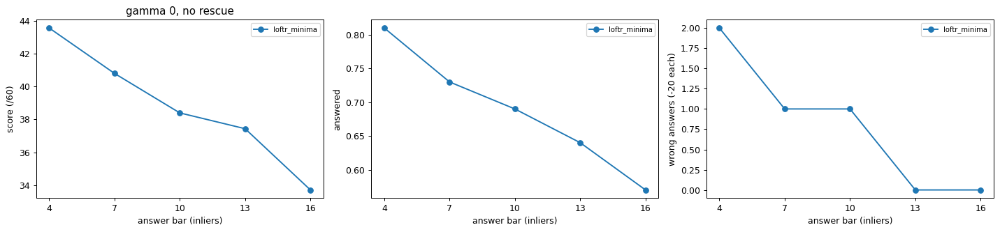

score by gamma (rows) and rescue rule (columns), matcher loftr_minima, bar 8


rescue
gamma


In [24]:
rows = []
for name in MATCHERS:
    for bar in BAR_LIST:
        for gamma in GAMMA_LIST:
            for rescue in RESCUE_LIST:
                cfg = dict(BASE, bar=bar, gamma=gamma, rescue=rescue)
                row = {"matcher": name, "bar": bar, "gamma": gamma, "rescue": str(rescue)}
                row.update(summarise(evaluate(cfg, name)))
                rows.append(row)
sweep_bar = pd.DataFrame(rows)
display(sweep_bar.sort_values("score (/60)", ascending=False).head(15).round(3).reset_index(drop=True))

plain = sweep_bar[(sweep_bar["gamma"] == 0.0) & (sweep_bar["rescue"] == "None")]
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for name in MATCHERS:
    part = plain[plain["matcher"] == name]
    axes[0].plot(part["bar"], part["score (/60)"], "o-", label=name)
    axes[1].plot(part["bar"], part["answered"], "o-", label=name)
    axes[2].plot(part["bar"], part["wrong answers"], "o-", label=name)
axes[0].set_ylabel("score (/60)")
axes[1].set_ylabel("answered")
axes[2].set_ylabel("wrong answers (-20 each)")
for axis in axes:
    axis.set_xlabel("answer bar (inliers)")
    axis.set_xticks(BAR_LIST)
    axis.legend(fontsize=8)
axes[0].set_title("gamma 0, no rescue")
plt.tight_layout()
plt.show()

print("score by gamma (rows) and rescue rule (columns), matcher %s, bar %d" % (MATCHERS[0], BASE["bar"]))
part = sweep_bar[(sweep_bar["matcher"] == MATCHERS[0]) & (sweep_bar["bar"] == BASE["bar"])]
display(part.pivot_table(index="gamma", columns="rescue", values="score (/60)").round(2))

## 8.3 Best setting per matcher, with both halves

The best row of the answer sweep for each matcher next to the baseline. If the best row's gain is not there in both halves, do not use it.

In [25]:
rows = []
for name in MATCHERS:
    part = sweep_bar[sweep_bar["matcher"] == name].sort_values("score (/60)", ascending=False)
    best = part.iloc[0]
    reference = summarise(base[name])
    rows.append({"matcher": name, "which": "baseline", "bar": BASE["bar"], "gamma": BASE["gamma"], "rescue": str(BASE["rescue"]),
                 "score (/60)": reference["score (/60)"], "first half": reference["first half"], "second half": reference["second half"],
                 "answered": reference["answered"], "wrong answers": reference["wrong answers"]})
    rows.append({"matcher": name, "which": "best of the sweep", "bar": best["bar"], "gamma": best["gamma"], "rescue": best["rescue"],
                 "score (/60)": best["score (/60)"], "first half": best["first half"], "second half": best["second half"],
                 "answered": best["answered"], "wrong answers": best["wrong answers"]})
display(pd.DataFrame(rows).round(3))

,matcher,which,bar,gamma,rescue,score (/60),first half,second half,answered,wrong answers
0,loftr_minima,baseline,8,1.0,None,39.6,40.56,38.64,0.71,1
1,loftr_minima,best of the sweep,13,4.0,"(4, 2.0)",45.6,45.36,45.84,0.78,0


# Part 9 · Sample figures: what the failures look like

For each kind of failure (the first stage that lost the photo, from the baseline setting), the worst `N_SAMPLES` photos, plus a few good ones. Each figure shows, left to right and top to bottom: the north-up canvas, the true map tile, the canvas over the true tile, the coarse score map (green star = truth, squares = best peaks); then the error of the first K peaks by coarse rank (green = right), the error of the M peaks after the DINO order, the inliers of those M candidates (green = right place, red line = answer bar), and the map tile of the candidate the pipeline chose.

target not in the K coarse peaks: 12 photos


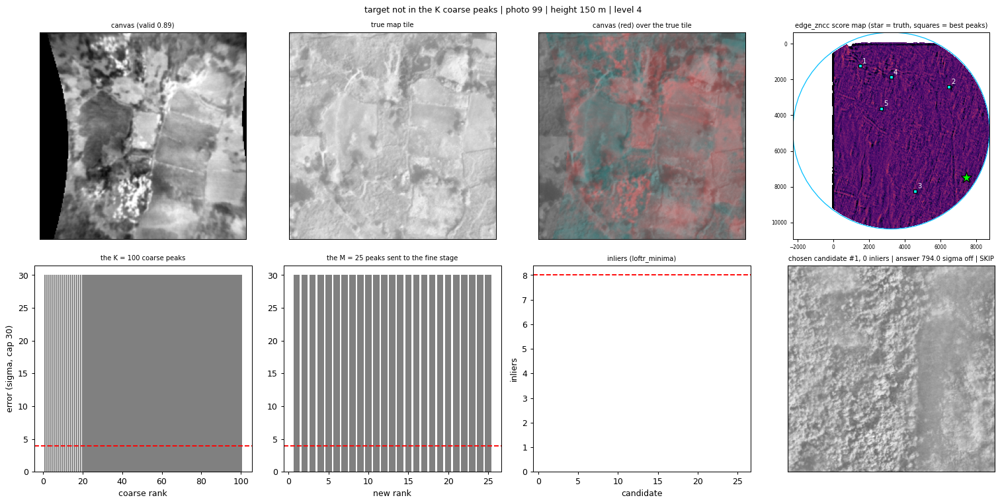

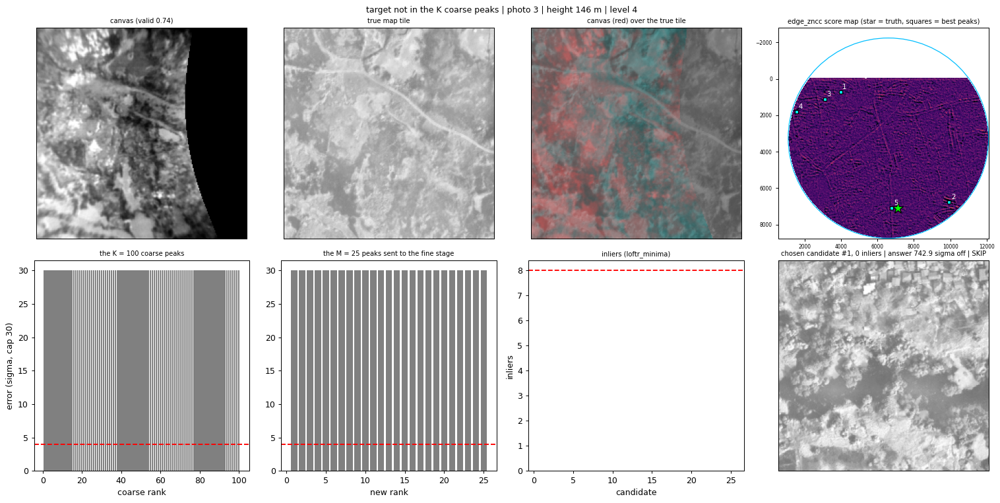

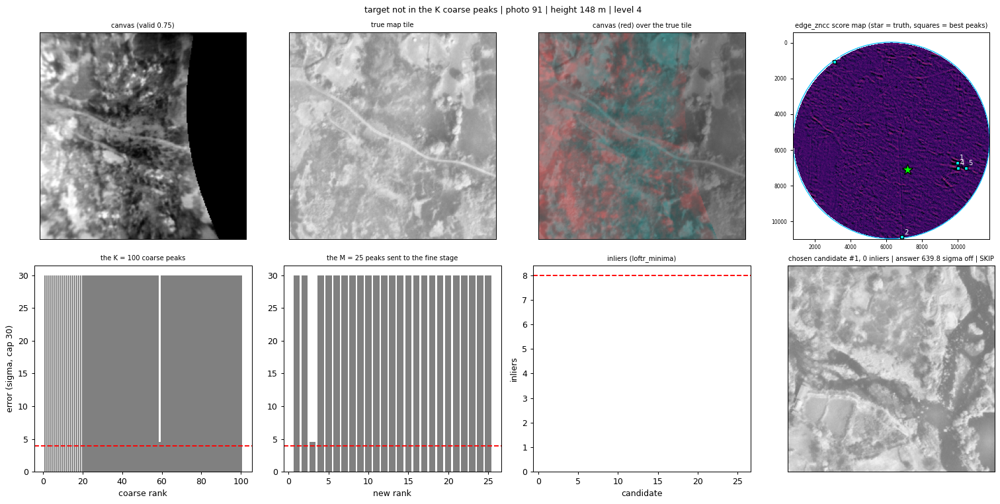

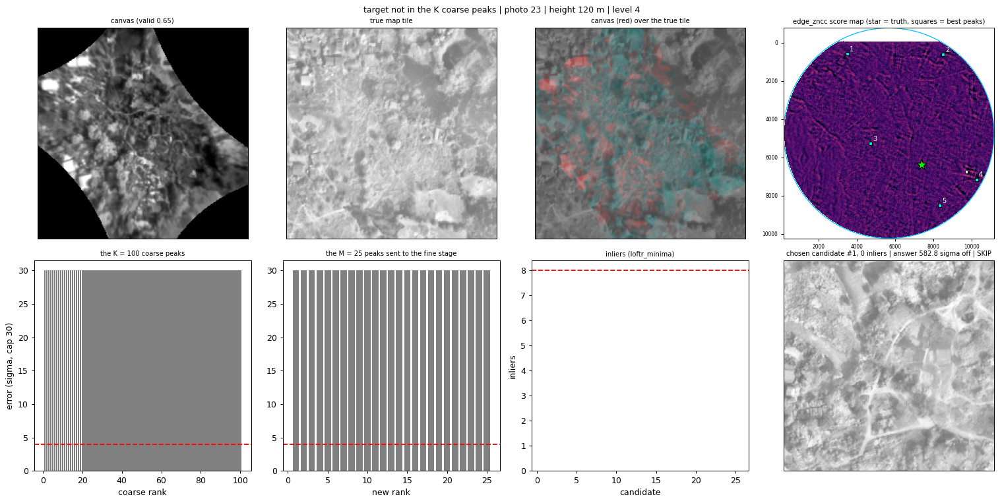

target in K but not in the M sent to fine: 0 photos
target in M but the wrong candidate was chosen: 3 photos


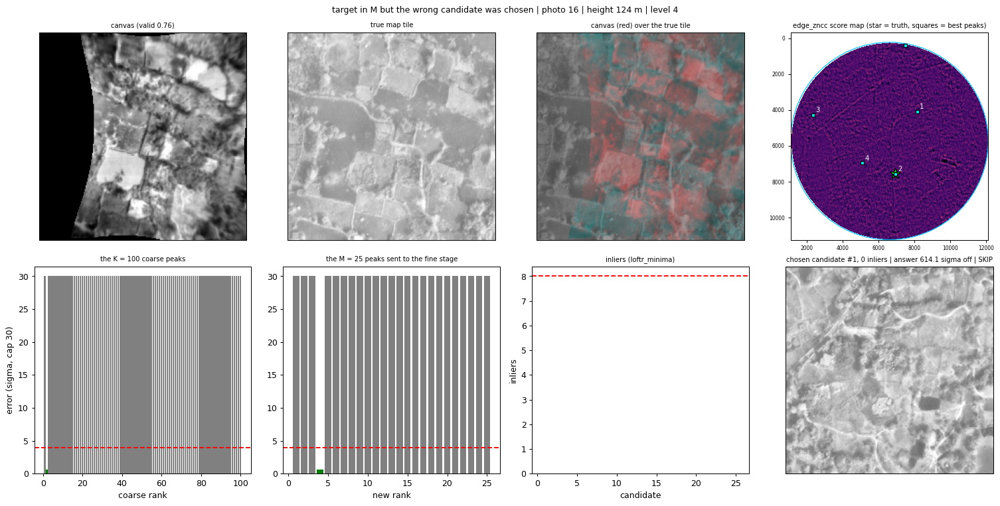

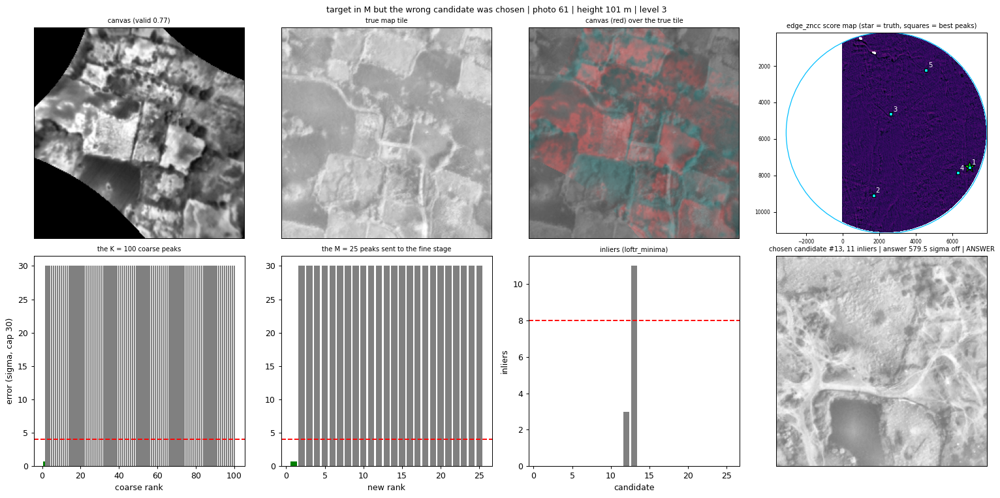

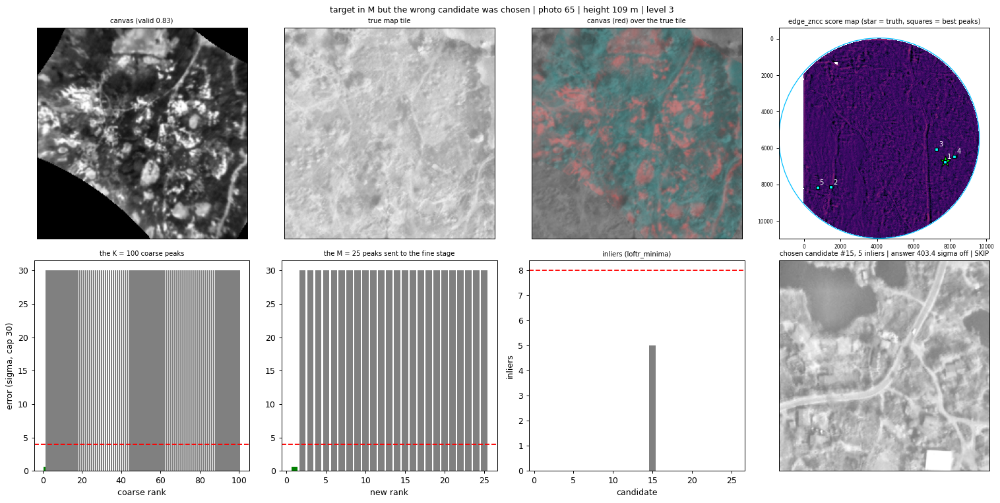

right candidate chosen but skipped (too few inliers): 15 photos


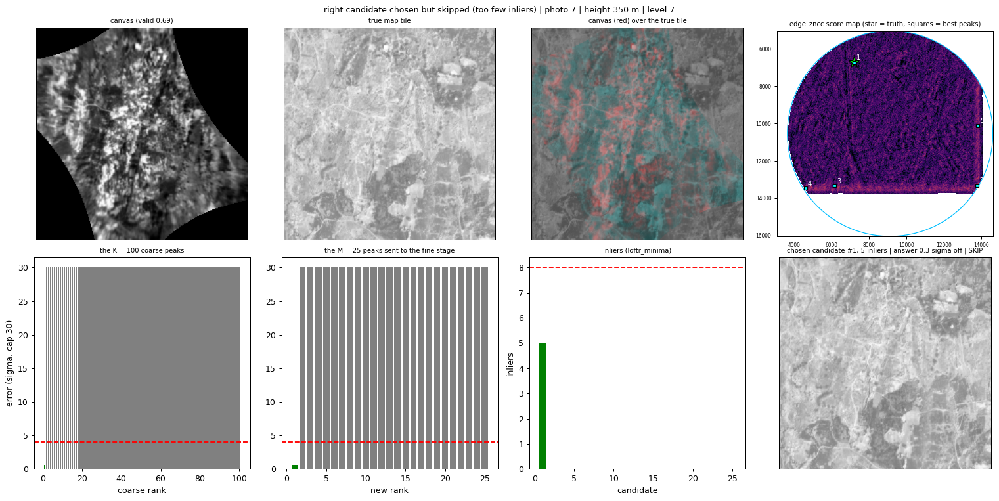

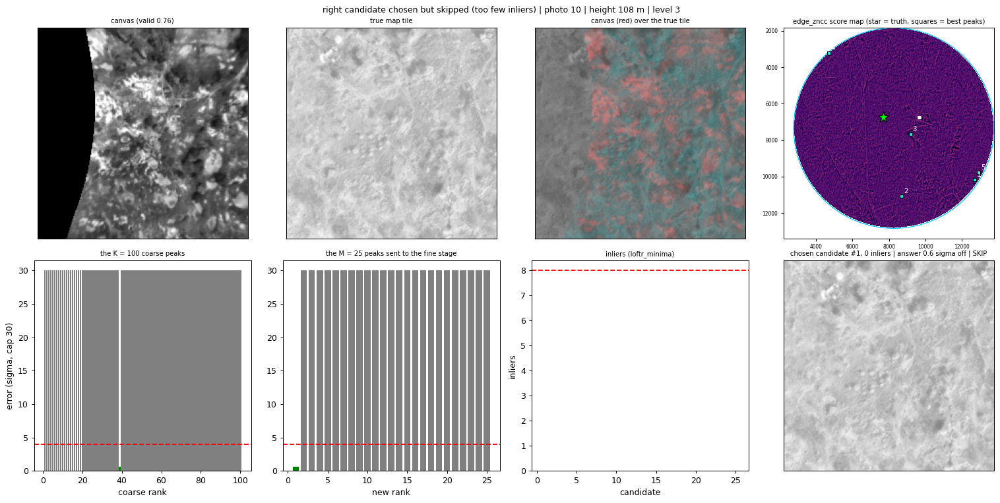

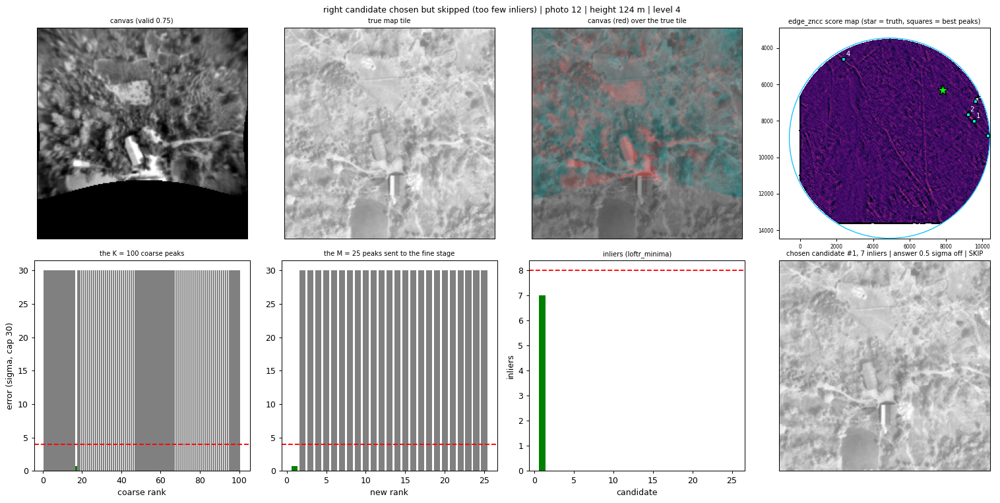

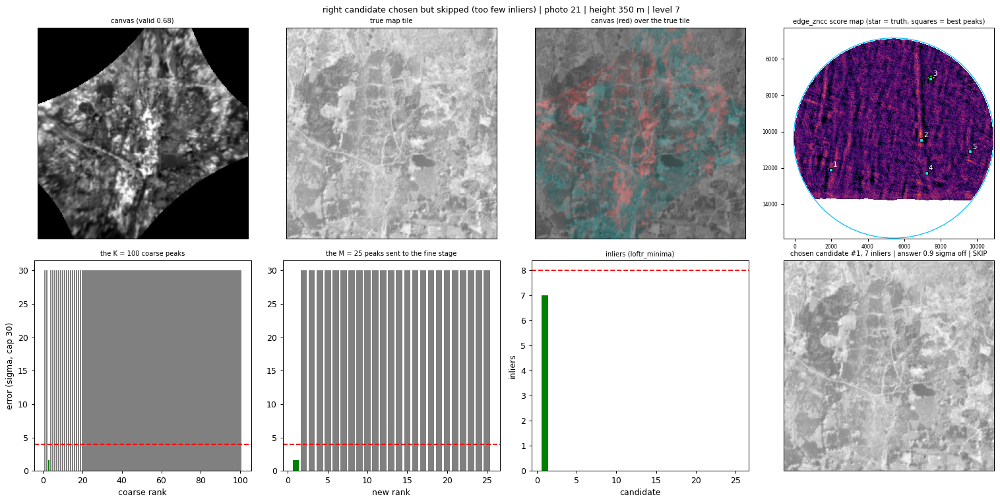

answered, but wrong place: 1 photos


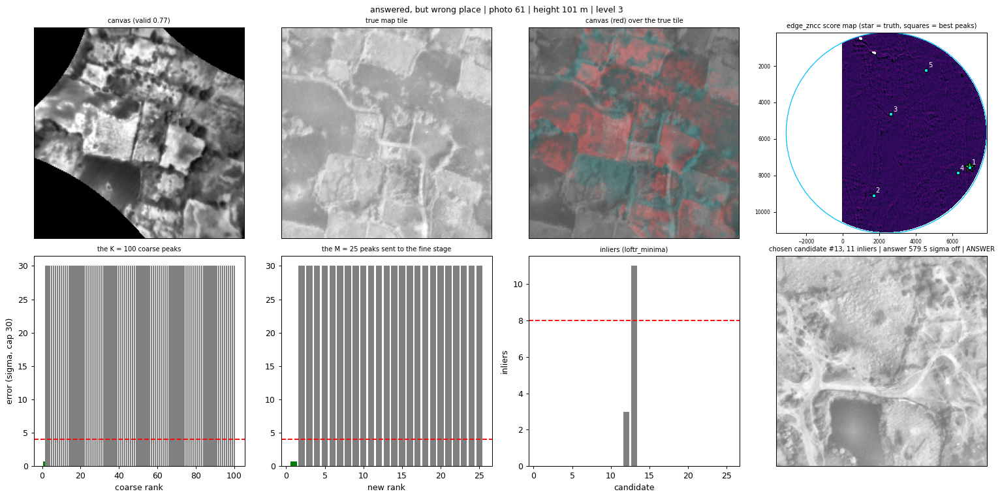

good: answered within 1 sigma: 65 photos


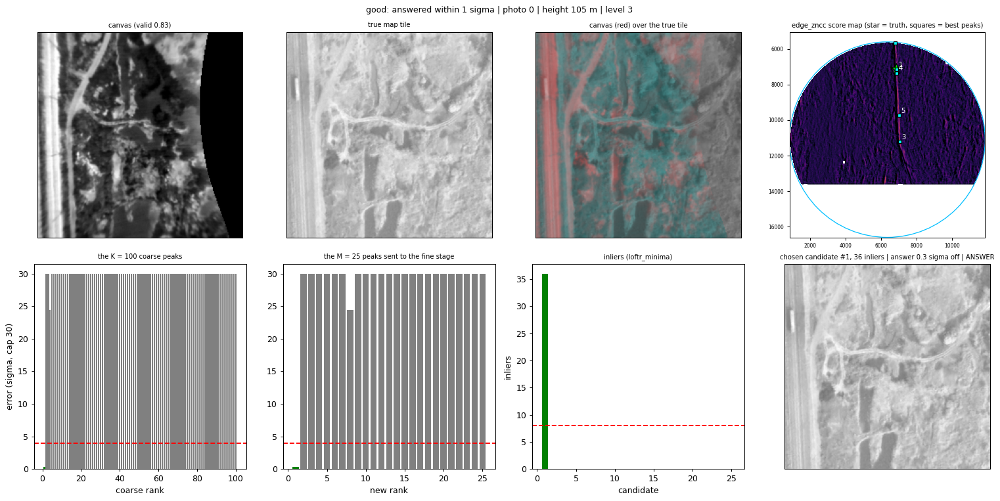

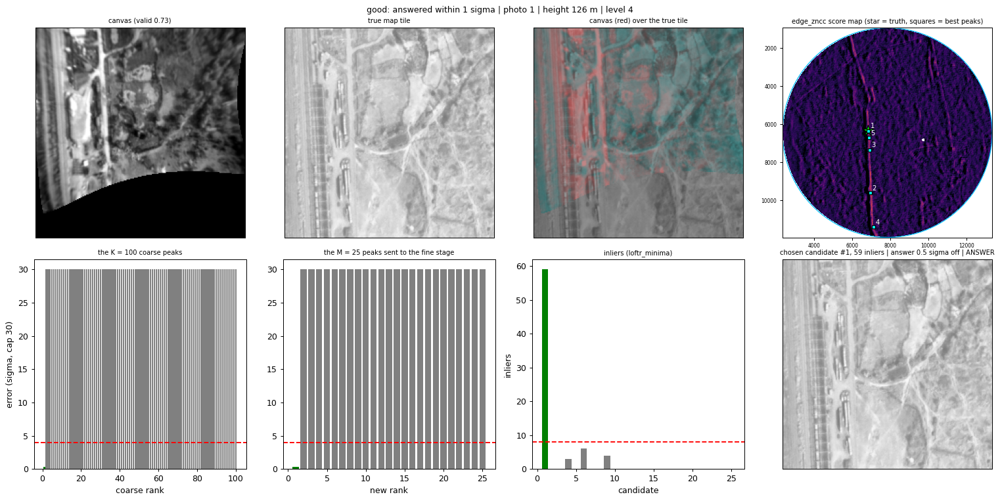

In [26]:
def draw_heat_map(axis, score_map, geometry, peaks, index, how_many=5):
    record = record_by_index[index]
    heat = score_map.cpu().numpy().copy()
    inside = geometry["inside"].cpu().numpy()
    heat[~inside | (heat <= -1)] = np.nan
    x_m = geometry["x_m"].cpu().numpy()
    y_m = geometry["y_m"].cpu().numpy()
    axis.imshow(heat, cmap="inferno", vmin=np.nanpercentile(heat, 5), vmax=np.nanmax(heat), extent=(x_m[0], x_m[-1], y_m[-1], y_m[0]))
    axis.add_patch(plt.Circle(test_set.priors[index], settings.DISC_RADIUS, fill=False, color="deepskyblue", lw=1.0))
    axis.plot(record["truth"][0], record["truth"][1], "*", color="lime", markersize=14, markeredgecolor="black")
    for rank in range(min(how_many, len(peaks))):
        if peaks[rank, 1] < 1e8:
            axis.plot(peaks[rank, 1], peaks[rank, 2], "s", color="cyan", markersize=4, markeredgecolor="black")
            axis.annotate(str(rank + 1), (peaks[rank, 1], peaks[rank, 2]), color="white", fontsize=8, xytext=(3, 3), textcoords="offset points")
    axis.set_title("%s score map (star = truth, squares = best peaks)" % PRIMARY, fontsize=8)
    axis.tick_params(labelsize=6)


def draw_sample(index, label):
    record = record_by_index[index]
    row, details = answer_for(record, fine[MATCHERS[0]][index], BASE)
    data = record["methods"][PRIMARY]
    truth = record["truth"]
    level = record["level"]
    true_tile = map_piece(level_images, level, truth[0], truth[1])
    blend = np.stack([true_tile, true_tile, true_tile], axis=-1) * 0.6
    blend[..., 0] = np.where(record["valid"], 0.5 * blend[..., 0] + 0.5 * record["canvas"], blend[..., 0])

    inputs = make_inputs(record["canvas"], record["valid"], level, test_set.priors[index], pipeline.families, pipeline.names)
    score_map = METHODS[PRIMARY](inputs)

    fig = plt.figure(figsize=(17, 8.6))
    grid = fig.add_gridspec(2, 4)
    show(fig.add_subplot(grid[0, 0]), record["canvas"] * record["valid"], "canvas (valid %.2f)" % record["valid_frac"])
    show(fig.add_subplot(grid[0, 1]), true_tile, "true map tile")
    show(fig.add_subplot(grid[0, 2]), np.clip(blend, 0, 1), "canvas (red) over the true tile")
    draw_heat_map(fig.add_subplot(grid[0, 3]), score_map, inputs["geometry"], data["short"], index)

    coarse_errors = data["err"][:BASE["K"]]
    axis = fig.add_subplot(grid[1, 0])
    axis.bar(range(1, len(coarse_errors) + 1), np.minimum(coarse_errors, 30), color=["green" if e <= FOUND_SIGMA else "gray" for e in coarse_errors])
    axis.axhline(FOUND_SIGMA, color="red", ls="--")
    axis.set_xlabel("coarse rank")
    axis.set_ylabel("error (sigma, cap 30)")
    axis.set_title("the K = %d coarse peaks" % BASE["K"], fontsize=8)

    axis = fig.add_subplot(grid[1, 1])
    axis.bar(range(1, len(details["errors"]) + 1), np.minimum(details["errors"], 30), color=["green" if e <= FOUND_SIGMA else "gray" for e in details["errors"]])
    axis.axhline(FOUND_SIGMA, color="red", ls="--")
    axis.set_xlabel("new rank")
    axis.set_title("the M = %d peaks sent to the fine stage" % BASE["M"], fontsize=8)

    inliers = fine[MATCHERS[0]][index]["inliers"][details["order"]]
    axis = fig.add_subplot(grid[1, 2])
    axis.bar(range(1, len(inliers) + 1), inliers, color=["green" if e <= FOUND_SIGMA else "gray" for e in details["errors"]])
    axis.axhline(BASE["bar"], color="red", ls="--")
    axis.set_xlabel("candidate")
    axis.set_ylabel("inliers")
    axis.set_title("inliers (%s)" % MATCHERS[0], fontsize=8)

    chosen_peak = data["short"][details["order"][details["chosen"]]]
    show(fig.add_subplot(grid[1, 3]), map_piece(level_images, level, chosen_peak[1], chosen_peak[2]),
         "chosen candidate #%d, %d inliers | answer %.1f sigma off | %s" % (details["chosen"] + 1, row["inliers"], row["err_sigma"], "ANSWER" if row["answered"] else "SKIP"))
    fig.suptitle("%s | photo %d | height %.0f m | level %d" % (label, index, record["height"], level), fontsize=10)
    plt.tight_layout()
    plt.show()
    del inputs
    if DEVICE == "cuda":
        torch.cuda.empty_cache()


table = base[MATCHERS[0]]
kinds = [
    ("target not in the K coarse peaks", table[~table["in_K"]].sort_values("err_sigma", ascending=False)),
    ("target in K but not in the M sent to fine", table[table["in_K"] & ~table["in_M"]]),
    ("target in M but the wrong candidate was chosen", table[table["in_M"] & ~table["chosen_right"]]),
    ("right candidate chosen but skipped (too few inliers)", table[table["chosen_right"] & ~table["answered"]]),
    ("answered, but wrong place", table[table["answered"] & (table["err_sigma"] > FOUND_SIGMA)]),
    ("good: answered within 1 sigma", table[table["answered"] & (table["err_sigma"] <= STRICT_SIGMA)]),
]
for label, part in kinds:
    print("=" * 100)
    print("%s: %d photos" % (label, len(part)))
    count_shown = N_SAMPLES if not label.startswith("good") else min(2, N_SAMPLES)
    for photo in list(part["photo"])[:count_shown]:
        draw_sample(int(photo), label)

# Part 10 · Save the tables

The per-photo table of the baseline (one row per photo and matcher) and the sweep tables go to `tests/Stage_Evaluation/`, so settings can be compared later without running anything again.

In [27]:
out_dir = ROOT / "tests" / "Stage_Evaluation"
out_dir.mkdir(parents=True, exist_ok=True)
tag = "%s_%s_K%d_M%d" % (DATA, PRIMARY, K_BASE, M_BASE)

for name in MATCHERS:
    table = base[name].copy()
    table["height"] = [record_by_index[p]["height"] for p in table["photo"]]
    table["valid_frac"] = [record_by_index[p]["valid_frac"] for p in table["photo"]]
    table["contrast"] = [record_by_index[p]["contrast"] for p in table["photo"]]
    table["edge_strength"] = [record_by_index[p]["edge_strength"] for p in table["photo"]]
    table["near_z"] = [record_by_index[p]["methods"][PRIMARY]["stats"]["near_z"] for p in table["photo"]]
    table["map_max_err_sigma"] = [record_by_index[p]["methods"][PRIMARY]["stats"]["argmax_err"] for p in table["photo"]]
    table.to_csv(out_dir / ("per_photo_%s_%s.csv" % (tag, name)), index=False)
    print("saved", out_dir / ("per_photo_%s_%s.csv" % (tag, name)))

sweep_kmw.to_csv(out_dir / ("sweep_K_M_weight_%s_%s.csv" % (tag, MATCHERS[0])), index=False)
sweep_bar.to_csv(out_dir / ("sweep_bar_gamma_rescue_%s.csv" % tag), index=False)
map_table.to_csv(out_dir / ("maps_%s.csv" % tag), index=False)
print("saved the sweep tables and the map table in", out_dir)


saved /home/voidness/Storage/Synced Folders/InterIIT Tech 15/IdeaForge-GeoLoc-InterIIT15/tests/Stage_Evaluation/per_photo_official_edge_zncc_K100_M25_loftr_minima.csv
saved the sweep tables and the map table in /home/voidness/Storage/Synced Folders/InterIIT Tech 15/IdeaForge-GeoLoc-InterIIT15/tests/Stage_Evaluation


In [28]:
if RUN_HEADINGS:
    heading_tag = "%s_%s_headings%d_scales%d_K%d_M%d" % (DATA, PRIMARY, len(HEADINGS), len(SCALE_FACTORS), HEADING_K, HEADING_M)
    heading_table.to_csv(out_dir / ("headings_per_photo_per_variant_%s.csv" % heading_tag), index=False)
    stage_table.to_csv(out_dir / ("headings_stage_table_%s.csv" % heading_tag))
    stage_loss.to_csv(out_dir / ("headings_points_lost_per_stage_%s.csv" % heading_tag), index=False)
    by_heading.to_csv(out_dir / ("headings_by_heading_%s.csv" % heading_tag), index=False)
    pd.DataFrame(heading_failures, columns=["photo", "error"]).to_csv(out_dir / ("headings_failures_%s.csv" % heading_tag), index=False)
    print("heading tables saved to", out_dir)
    stage_time_table.to_csv(out_dir / ("time_per_stage_%s.csv" % tag), index=False)
    cost_table.to_csv(out_dir / ("time_cost_of_K_and_M_%s.csv" % tag))
    query_stage_table.to_csv(out_dir / ("time_per_query_%s.csv" % heading_tag), index=False)
    decision_table.to_csv(out_dir / ("decision_steps_per_photo_%s.csv" % heading_tag), index=False)
    build_table.to_csv(out_dir / ("decision_steps_summary_%s.csv" % heading_tag), index=False)
    decision_sweep.to_csv(out_dir / ("decision_steps_sweep_%s.csv" % heading_tag), index=False)
    phase_table.to_csv(out_dir / ("all_phases_%s.csv" % heading_tag), index=False)
    print("time and decision-step tables saved to", out_dir)

heading tables saved to /home/voidness/Storage/Synced Folders/InterIIT Tech 15/IdeaForge-GeoLoc-InterIIT15/tests/Stage_Evaluation
time and decision-step tables saved to /home/voidness/Storage/Synced Folders/InterIIT Tech 15/IdeaForge-GeoLoc-InterIIT15/tests/Stage_Evaluation


**Caveats.** The inflation-guard rows of Part 6.9 are a replay on stored inliers multiplied by a factor, not a new camera; the guard's settings were pre-registered and confirmed on one other NUDT flight set (`tests/Test_Iteration_7/results/preregistered_guard.json`). The photos and the map are from the development set; the real evaluation uses a different map. With 100 photos every share has an interval of several percentage points (for a share near 0.9 about plus or minus 0.06), and the sweeps are searched on the photos they are scored on. The learned fusion was trained on the NUDT (Changsha) photos, so the official set tests it on another city. The fine stage was run on the coarse order of the primary method; the other coarse method is evaluated up to stage 3 only. To compare data sets or seeds, run the notebook again with the setting changed and compare the saved tables photo by photo. The decision steps (agreement of 2 queries within 1 sigma, escalation bar 11) were chosen on development photos in Test_Iteration_3 and are replayed here on the stored queries, so their gain is an upper estimate until a run on unseen photos confirms it. The seconds are for this computer, not the Jetson. The time of the fine and DINO steps for K and M other than `K_MAX` is scaled from the measured time per place.